In [1]:
import numpy as np
from astropy.io import fits
import matplotlib.pyplot as plt
import math
from scipy import stats
from matplotlib.colors import hsv_to_rgb
from astropy.wcs import WCS
import statsmodels.api as sm
import pandas as pd
from scipy.optimize import curve_fit

# Masking COLTE outputs with SNR

In [259]:
data_path = "/Users/kyriakos.trakakis/Downloads/CHIMPS_COHRS/13CO/"
colte_path = "/Users/kyriakos.trakakis/COLTE/"

clusters_file = data_path + "FGN_027_037_13CO_23arcsec_aligned_SNR_min_del_2_parallel_clusters.fits"

In [270]:
## FUGIN case

colte_file    = colte_path + "colte_FGN_027_037_23arcsec_Tex_scimes_mask.fits"
snr_file      = data_path + "FGN_027_037_13CO_23arcsec_aligned_SNR.fits"
data_file     = data_path + "FGN_027_037_13CO_23arcsec_aligned.fits"

In [285]:
## CHIMPS case

colte_file    = colte_path + "colte_CHIMPS_027_037_23arcsec_aligned_Tex_scimes_mask.fits"
snr_file      = data_path + "CHIMPS_027_037_13CO_23arcsec_aligned_SNR.fits"
data_file     = data_path + "CHIMPS_027_037_13CO_23arcsec_aligned.fits"

In [286]:
with fits.open(snr_file) as hdul:
    snr        = hdul[0].data
    snr_header = hdul[0].header 
    
with fits.open(clusters_file) as hdul:
    clust_data   = hdul[0].data
    clust_header = hdul[0].header 


with fits.open(colte_file) as hdul:
    colte_data   = hdul[0].data
    colte_header = hdul[0].header 
    
with fits.open(data_file) as hdul:
    data        = hdul[0].data
    data_header = hdul[0].header 

### SNR and NaN Masking ###    

thresh = 0
if thresh > 0:
    mask_snr = (snr >thresh)
else:
    mask_snr = np.ones_like(colte_data, dtype=bool)

colte_masked = np.where(mask_snr,colte_data, 0)
data_masked  = np.where(mask_snr,data, 0)

mask_nan     = ~np.isnan(colte_masked)

colte_masked = np.where(mask_nan,colte_masked,0)
data_masked = np.where(mask_nan,data_masked,0)

# Velocity masking, optional

nchan = colte_masked.shape[0]

crval3 = colte_header["CRVAL3"]
crpix3 = colte_header["CRPIX3"]
cdelt3 = colte_header["CDELT3"]

channels = np.arange(nchan)
vel = crval3 + (channels + 1 - crpix3) * cdelt3

if abs(cdelt3) > 100:
    vel = vel / 1000.0
v0 = 0
v1 = 120

mask_v = (vel >= v0) & (vel < v1)

colte_masked = colte_masked[mask_v, :, :]  #Optional
data_masked  = data_masked[mask_v, :, :]   # Optional

# Weight 

In [287]:
colte_masked_filename = colte_file.replace(".fits", f"_snr{thresh}.fits")
#colte_masked_filename = colte_file.replace(".fits", f"_snr{thresh}_v{v0}-{v1}.fits")

hdu = fits.PrimaryHDU(data=colte_masked, header=colte_header)
#hdu.writeto(colte_masked_filename, overwrite=True)

weighted                = np.sum(colte_masked * data_masked, axis=0) / np.sum(data_masked, axis=0)
#colte_weighted_filename = colte_file.replace(".fits", f"_snr{thresh}_weighted.fits")
colte_weighted_filename = colte_file.replace(".fits", f"_snr{thresh}_weighted_v{v0}-{v1}.fits")

hdu = fits.PrimaryHDU(data=weighted, header=colte_header)
hdu.writeto(colte_weighted_filename, overwrite=True)

# Making ratio maps

In [2]:
path_13 = "/Users/kyriakos.trakakis/Downloads/CHIMPS_COHRS/13CO/"
path_12 = "/Users/kyriakos.trakakis/Downloads/CHIMPS_COHRS/12CO/"

In [3]:
region  = "027_037"


file_13 = path_13 + f"FGN_{region}_13CO_23arcsec_aligned.fits"
file_12 = path_12 + f"FGN_{region}_12CO_23arcsec_aligned.fits"
SNR_13  = path_13 + f"FGN_{region}_13CO_23arcsec_aligned_SNR.fits"
SNR_12  = path_12 + f"FGN_{region}_12CO_23arcsec_aligned_SNR.fits"

In [9]:
with fits.open(file_13) as hdul:
    data_13        = hdul[0].data
    data_13_header = hdul[0].header

with fits.open(file_12) as hdul:
    data_12        = hdul[0].data
    data_12_header = hdul[0].header
    
with fits.open(SNR_13) as hdul:
    snr_13 = hdul[0].data
    
with fits.open(SNR_12) as hdul:
    snr_12 = hdul[0].data

In [10]:
thresh = 3

mask_snr = (snr_12 > thresh) & (snr_13 > thresh)
                        
data_13 = np.where(mask_snr, data_13, 0)
data_12 = np.where(mask_snr, data_12, 0)

mask_nan = (~np.isnan(data_13)) & (~np.isnan(data_12)) & (data_13!=0)

data_13 = np.where(mask_nan, data_13, 0)
data_12 = np.where(mask_nan, data_12, 0)

In [11]:
## 3D ratio map

ratio = data_12 / data_13

ratio_filename_3d = path_13 + f"FGN_{region}_12_13_ratio_SNR{thresh}_3d.fits"

hdu = fits.PrimaryHDU(ratio, header=data_13_header)
hdu.writeto(ratio_filename, overwrite=True

/var/folders/my/spqrhq7n74bcr2n7xfhc9hhr0000gp/T/ipykernel_46816/2991969185.py:1: RuntimeWarning: invalid value encountered in divide
  ratio = data_12 / data_13


In [13]:
## 2D ratio map

data_12_2d = np.nansum(data_12, axis = 0)
data_13_2d = np.nansum(data_13, axis = 0)

ratio_2d = data_12_2d / data_13_2d

ratio_filename_2d = path_13 + f"FGN_{region}_12_13_ratio_SNR{thresh}_2d.fits"

hdu = fits.PrimaryHDU(ratio_2d, header=data_13_header)
hdu.writeto(ratio_filename_2d, overwrite=True)

## I suspect adding these over the entire velocity range is not gonna produce significant or meaningful results. 
## See Evans_plot_generator_3ISO_1-0.py for an idea.

/var/folders/my/spqrhq7n74bcr2n7xfhc9hhr0000gp/T/ipykernel_46816/130914839.py:6: RuntimeWarning: invalid value encountered in divide
  ratio_2d = data_12_2d / data_13_2d


In [23]:
## Attempt of idea mentioned above. 
nchan = data_13.shape[0]

crval3 = data_13_header["CRVAL3"]
crpix3 = data_13_header["CRPIX3"]
cdelt3 = data_13_header["CDELT3"]

channels = np.arange(nchan)
vel = crval3 + (channels + 1 - crpix3) * cdelt3

if abs(cdelt3) > 100:
    vel = vel / 1000.0

vlow, vhigh = 70 ,110  
bins = np.arange(vlow, vhigh + 10, 10)

for i in range(len(bins) - 1):

    v0 = bins[i]
    v1 = bins[i + 1]

    mask = (vel >= v0) & (vel < v1)

    cube_12 = data_12[mask, :, :]
    cube_13 = data_13[mask, :, :]

    data_12_2d = np.nansum(cube_12, axis = 0)
    data_13_2d = np.nansum(cube_13, axis = 0)    

    ratio = data_12_2d / data_13_2d

    ratio_filename_2d = path_13 + f"FGN_{region}_12_13_ratio_SNR{thresh}_2d_v{v0}-{v1}.fits"

    hdu = fits.PrimaryHDU(ratio_2d, header=data_13_header)
    hdu.writeto(ratio_filename_2d, overwrite=True)

## I don't like this. Maybe if I scaled this so it's not just a sum of ratios?

/var/folders/my/spqrhq7n74bcr2n7xfhc9hhr0000gp/T/ipykernel_46816/809104169.py:31: RuntimeWarning: invalid value encountered in divide
  ratio = data_12_2d / data_13_2d


/var/folders/my/spqrhq7n74bcr2n7xfhc9hhr0000gp/T/ipykernel_16705/2993951853.py:148: RuntimeWarning: divide by zero encountered in divide
  a = sigma1_eff / I1
/var/folders/my/spqrhq7n74bcr2n7xfhc9hhr0000gp/T/ipykernel_16705/2993951853.py:149: RuntimeWarning: divide by zero encountered in divide
  b = sigma2_eff / I2
/Users/kyriakos.trakakis/anaconda3/lib/python3.11/site-packages/matplotlib/colors.py:3738: RuntimeWarning: invalid value encountered in cast
  i = (h * 6.0).astype(int)
Set OBSGEO-B to    19.822919 from OBSGEO-[XYZ].
Set OBSGEO-H to     4117.025 from OBSGEO-[XYZ]'. [astropy.wcs.wcs]


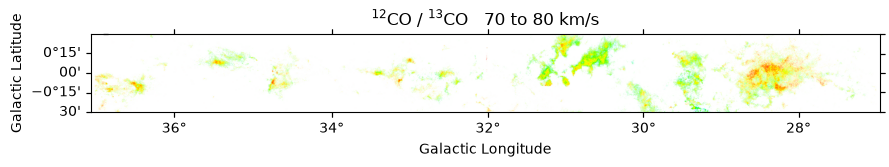

/var/folders/my/spqrhq7n74bcr2n7xfhc9hhr0000gp/T/ipykernel_16705/2993951853.py:148: RuntimeWarning: divide by zero encountered in divide
  a = sigma1_eff / I1
/var/folders/my/spqrhq7n74bcr2n7xfhc9hhr0000gp/T/ipykernel_16705/2993951853.py:149: RuntimeWarning: divide by zero encountered in divide
  b = sigma2_eff / I2
/Users/kyriakos.trakakis/anaconda3/lib/python3.11/site-packages/matplotlib/colors.py:3738: RuntimeWarning: invalid value encountered in cast
  i = (h * 6.0).astype(int)
Set OBSGEO-B to    19.822919 from OBSGEO-[XYZ].
Set OBSGEO-H to     4117.025 from OBSGEO-[XYZ]'. [astropy.wcs.wcs]


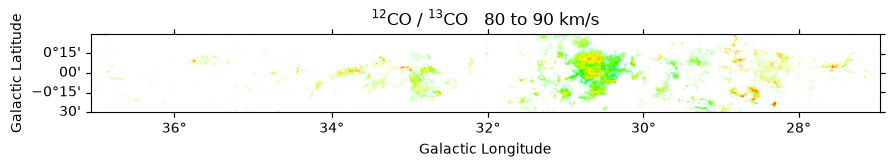

/var/folders/my/spqrhq7n74bcr2n7xfhc9hhr0000gp/T/ipykernel_16705/2993951853.py:148: RuntimeWarning: divide by zero encountered in divide
  a = sigma1_eff / I1
/var/folders/my/spqrhq7n74bcr2n7xfhc9hhr0000gp/T/ipykernel_16705/2993951853.py:149: RuntimeWarning: divide by zero encountered in divide
  b = sigma2_eff / I2
/Users/kyriakos.trakakis/anaconda3/lib/python3.11/site-packages/matplotlib/colors.py:3738: RuntimeWarning: invalid value encountered in cast
  i = (h * 6.0).astype(int)
Set OBSGEO-B to    19.822919 from OBSGEO-[XYZ].
Set OBSGEO-H to     4117.025 from OBSGEO-[XYZ]'. [astropy.wcs.wcs]


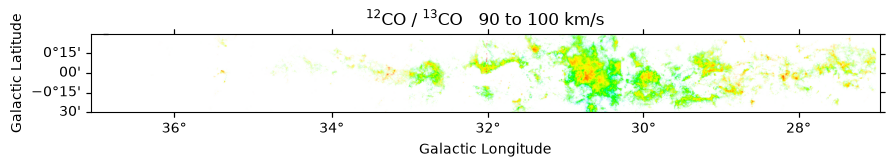

/var/folders/my/spqrhq7n74bcr2n7xfhc9hhr0000gp/T/ipykernel_16705/2993951853.py:148: RuntimeWarning: divide by zero encountered in divide
  a = sigma1_eff / I1
/var/folders/my/spqrhq7n74bcr2n7xfhc9hhr0000gp/T/ipykernel_16705/2993951853.py:149: RuntimeWarning: divide by zero encountered in divide
  b = sigma2_eff / I2
/Users/kyriakos.trakakis/anaconda3/lib/python3.11/site-packages/matplotlib/colors.py:3738: RuntimeWarning: invalid value encountered in cast
  i = (h * 6.0).astype(int)
Set OBSGEO-B to    19.822919 from OBSGEO-[XYZ].
Set OBSGEO-H to     4117.025 from OBSGEO-[XYZ]'. [astropy.wcs.wcs]


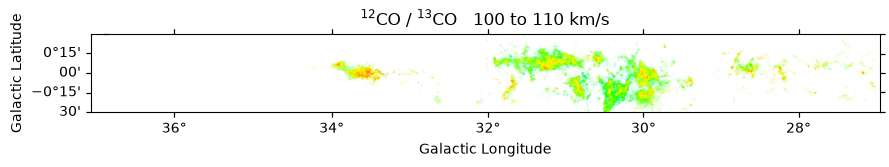

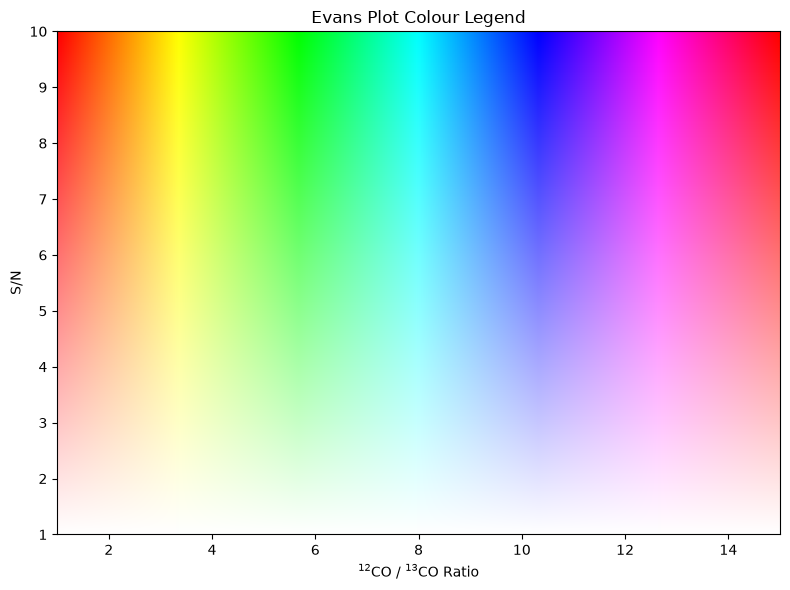

In [84]:
## Scaled version based on the way I created Evans plots. Saves the ratio maps (preferably ratio_clip),
## the main thing we want from the Evans plots.

region = "027_037"

# choose any two:
isotopologues = ["12", "13"]   # Thicker one first!

rmin = 1
rmax = 15
snrmax = 10

# =====================================================
# PATHS
# =====================================================

paths = {
    "12": "/Users/kyriakos.trakakis/Downloads/CHIMPS_COHRS/12CO/",
    "13": "/Users/kyriakos.trakakis/Downloads/CHIMPS_COHRS/13CO/",
    "18": "/Users/kyriakos.trakakis/Downloads/CHIMPS_COHRS/C18O/",
}

# =====================================================
# REGION NOISE VALUES
# =====================================================

if region == "017_027":
    sigma = {"12": 0.91, "13": 0.51, "18": 0.52}
    vlow, vhigh = 0, 130

elif region == "027_037":
    sigma = {"12": 1.24, "13": 0.54, "18": 0.59}
    vlow, vhigh = 70, 110

else:
    sigma = {"12": 0.66, "13": 0.26, "18": 0.31}
    vlow, vhigh = -10, 10

# =====================================================
# HELPERS
# =====================================================

def iso_label(iso):
    if iso == "18":
        return r"C$^{18}$O"
    else:
        return rf"$^{{{iso}}}$CO"


def cube_filename(region, iso):
    if iso == "18":
        return f"FGN_{region}_C18O_23arcsec_aligned.fits"
    else:
        return f"FGN_{region}_{iso}CO_23arcsec_aligned.fits"


def snr_filename(region, iso):
    if iso == "18":
        return f"FGN_{region}_C18O_23arcsec_aligned_SNR.fits"
    else:
        return f"FGN_{region}_{iso}CO_23arcsec_aligned_SNR.fits"


# =====================================================
# LOAD DATA
# =====================================================

data = {}
snr_cube = {}

for iso in ["12", "13", "18"]:

    file_cube = paths[iso] + cube_filename(region, iso)
    file_snr  = paths[iso] + snr_filename(region, iso)

    data[iso] = fits.getdata(file_cube)
    snr_cube[iso] = fits.getdata(file_snr)

# Use first selected tracer for header/WCS
iso_ref = isotopologues[0]
file_ref = paths[iso_ref] + cube_filename(region, iso_ref)

with fits.open(file_ref) as hdul:
    header = hdul[0].header
    cube_ref = hdul[0].data

# =====================================================
# VELOCITY AXIS
# =====================================================

nchan = cube_ref.shape[0]

crval3 = header["CRVAL3"]
crpix3 = header["CRPIX3"]
cdelt3 = header["CDELT3"]

channels = np.arange(nchan)
vel = crval3 + (channels + 1 - crpix3) * cdelt3

if abs(cdelt3) > 100:
    vel = vel / 1000.0

# =====================================================
# SELECT ACTIVE TRACERS
# =====================================================

iso1, iso2 = isotopologues

# =====================================================
# LOOP THROUGH VELOCITY BLOCKS
# =====================================================

bins = np.arange(vlow, vhigh + 10, 10)

for i in range(len(bins) - 1):

    v0 = bins[i]
    v1 = bins[i + 1]

    mask = (vel >= v0) & (vel < v1)

    cube1 = data[iso1][mask, :, :]
    cube2 = data[iso2][mask, :, :]

    # -----------------------------------------
    # Integrated intensities
    # -----------------------------------------

    I1 = np.nansum(cube1, axis=0)
    I2 = np.nansum(cube2, axis=0)

    # -----------------------------------------
    # Ratio
    # -----------------------------------------

    ratio = np.full_like(I1, np.nan, dtype=float)

    good = I2 > 0
    ratio[good] = I1[good] / I2[good]

    # -----------------------------------------
    # SNR estimate
    # -----------------------------------------
    
    sigma1_eff = sigma[iso1] * np.sqrt(nchan)
    sigma2_eff = sigma[iso2] * np.sqrt(nchan)

    a = sigma1_eff / I1
    b = sigma2_eff / I2

    snr = 1.0 / (a**2 + b**2)

    # -----------------------------------------
    # HSV conversion
    # -----------------------------------------

    ratio_clip = np.clip(ratio, rmin, rmax)

    H = (ratio_clip - rmin) / (rmax - rmin)

    # Original white noise
    S = np.clip(snr, 1, snrmax)
    S = (S-1)/(snrmax-1)

    V = np.ones_like(H)

    # grey at SNR=0, bright at high SNR
    #S = np.clip(snr, 0, snrmax) / snrmax
    #V = 0.5 + 0.5 * S

    HSV = np.dstack((H, S, V))
    RGB = hsv_to_rgb(HSV)

    RGB[np.isnan(ratio)] = 1

    # -----------------------------------------
    # Plot
    # -----------------------------------------

    wcs2d = WCS(header).celestial
    header2d = wcs2d.to_header()

    fig = plt.figure(figsize=(9, 7))
    ax = fig.add_subplot(111, projection=wcs2d)

    ax.imshow(RGB, origin="lower")

    ax.set_xlabel("Galactic Longitude")
    ax.set_ylabel("Galactic Latitude")

    ax.set_title(
        f"{iso_label(iso1)} / {iso_label(iso2)}   "
        f"{v0} to {v1} km/s"
    )
    region_mod = region.replace("_","-")
    plt.tight_layout()
    plt.show()
# =====================================================
# 2D LEGEND
# =====================================================

nx, ny = 300, 300

ratio_vals = np.linspace(rmin, rmax, nx)
snr_vals   = np.linspace(1, snrmax, ny)  # Can also do 0,snrmax

RR, SS = np.meshgrid(ratio_vals, snr_vals)

H_leg = (RR - rmin) / (rmax - rmin)
#S_leg = SS / snrmax  # For gray
S_leg = (SS - 1) / 9.0
#V_leg = 0.5 + 0.5 * S_leg # For gray
V_leg = np.ones_like(H_leg)

HSV_leg = np.dstack((H_leg, S_leg, V_leg))
RGB_leg = hsv_to_rgb(HSV_leg)

plt.figure(figsize=(8, 6))
plt.imshow(
    RGB_leg,
    origin="lower",
    aspect="auto",
    extent=[rmin, rmax, 1, snrmax]  # Can also do 0, snrmax
)

plt.xlabel(f"{iso_label(iso1)} / {iso_label(iso2)} Ratio")
plt.ylabel("S/N")
plt.title("Evans Plot Colour Legend")

plt.tight_layout()
plt.show()

In [6]:
## Masking LTE map by scimes clouds

data_path    = "/Users/kyriakos.trakakis/Downloads/Mopra_FGN_project/Mopra/12CO/"
#data_path    = "/Users/kyriakos.trakakis/Downloads/CHIMPS_COHRS/13CO/"
colte_path   = "/Users/kyriakos.trakakis/COLTE/"

clusters_file = "/Users/kyriakos.trakakis/Downloads/Mopra_FGN_project/Mopra/13CO/G340-350-13CO_smallercube_05res_min_del_2_parallel_clusters.fits"
#clusters_file = "/Users/kyriakos.trakakis/Downloads/Mopra_FGN_project/Mopra/13CO/G250-260-13CO_smallercube_05res_min_del_2_parallel_clusters.fits"

In [7]:
## FUGIN case

#colte_file    = colte_path + "colte_FGN_027_037_23arcsec_Tex.fits"
colte_file    = data_path + "G340-350-12CO_smallercube_05res.fits"
snr_file      = data_path + "FGN_027_037_13CO_23arcsec_aligned_SNR.fits"

In [45]:
## CHIMPS case

colte_file    = colte_path + "colte_CHIMPS_027_037_23arcsec_aligned_Tex.fits"
#snr_file      = data_path + "CHIMPS_027_037_13CO_23arcsec_aligned_SNR.fits"

colte_file    = data_path + "CHIMPS_027_037_13CO_23arcsec_aligned.fits"

In [8]:
#with fits.open(snr_file) as hdul:
#    snr        = hdul[0].data
#    snr_header = hdul[0].header 
    
with fits.open(clusters_file) as hdul:
    clust_data   = hdul[0].data
    clust_header = hdul[0].header 
    
with fits.open(colte_file) as hdul:
    colte_data   = hdul[0].data
    colte_header = hdul[0].header 

In [9]:
### SNR, NaN and Cloud Masking ###    

thresh = 0

if thresh > 0:
    mask_snr = (snr >thresh)
else:
    mask_snr = np.ones_like(colte_data, dtype=bool)

colte_masked = np.where(mask_snr,colte_data, 0)


mask_nan     = ~np.isnan(colte_masked)
colte_masked = np.where(mask_nan,colte_masked,0)

mask_scimes  = (clust_data !=-1)
colte_masked = np.where(mask_scimes,colte_masked,0)

In [10]:
#colte_masked_filename = colte_file.replace(".fits", f"_scimes_mask_snr{thresh}.fits")
colte_masked_filename = colte_file.replace(".fits", "_scimes_mask.fits")

hdu = fits.PrimaryHDU(data=colte_masked, header=colte_header)
hdu.writeto(colte_masked_filename, overwrite=True)

In [79]:
colte_N13_filename = colte_path + "colte_CHIMPS_027_037_23arcsec_aligned_N13CO.fits"

with fits.open(colte_N13_filename) as hdul:
    colte_N13_data   = hdul[0].data
    colte_N13_header = hdul[0].header 

colte_N13_data = np.where(~np.isnan(colte_N13_data), colte_N13_data, 0)

nchan = colte_N13_data.shape[0]

crval3 = colte_N13_header["CRVAL3"]
crpix3 = colte_N13_header["CRPIX3"]
cdelt3 = colte_N13_header["CDELT3"]

channels = np.arange(nchan)
vel = crval3 + (channels + 1 - crpix3) * cdelt3

if abs(cdelt3) > 100:
    vel = vel / 1000.0
v0 = 0
v1 = 120

mask = (vel >= v0) & (vel < v1)

cube = colte_N13_data[mask, :, :]
coll = np.nansum(cube, axis=0) /2

colte_N13_col_filename_2d = path_13 + f"CHIMPS_027-037_colte_N13CO_v{v0}-{v1}.fits"

hdu = fits.PrimaryHDU(coll, header=colte_N13_header)
hdu.writeto(colte_N13_col_filename_2d, overwrite=True)

# Density histograms

In [49]:
data_path = "/Users/kyriakos.trakakis/Downloads/CHIMPS_COHRS/13CO/"

scimes = 1

# Original data
FGN_colte_file    = data_path + "FGN_027-037_colte_NH2_v0-120.fits"
CHIMPS_colte_file = data_path + "CHIMPS_027-037_colte_NH2_v0-120.fits"
FGN_X_file        = data_path + "FGN_027_037_13CO_23arcsec_aligned_NH2_X_v0-120.fits"
FGN_X_file_12     = data_path + "FGN_027_037_12CO_23arcsec_aligned_NH2_X_v0-120.fits"
CHIMPS_X_file     = data_path + "CHIMPS_027_037_13CO_23arcsec_aligned_NH2_X_v0-120.fits"
COHRS_X_file      = data_path + "COHRS_027_037_12CO_23arcsec_aligned_NH2_X_v0-120.fits"
W13_file          = data_path + "FGN_027_037_13CO_23arcsec_aligned_integrated_v0-120.fits"

# Scimes only
if scimes == 1:
    FGN_colte_file    = data_path + "FGN_027-037_colte_NH2_v0-120_scimes_mask.fits"
    CHIMPS_colte_file = data_path + "CHIMPS_027-037_colte_NH2_v0-120_scimes_mask.fits"
    FGN_X_file        = data_path + "FGN_027_037_13CO_23arcsec_aligned_NH2_X_v0-120_scimes_mask.fits"
    FGN_X_file_12     = data_path + "FGN_027_037_12CO_23arcsec_aligned_NH2_X_v0-120_scimes_mask.fits"
    CHIMPS_X_file     = data_path + "CHIMPS_027_037_13CO_23arcsec_aligned_NH2_X_v0-120_scimes_mask.fits"
    COHRS_X_file      = data_path + "COHRS_027_037_12CO_23arcsec_aligned_NH2_X_v0-120_scimes_mask.fits"
    W13_file          = data_path + "FGN_027_037_13CO_23arcsec_aligned_integrated_v0-120_scimes_mask.fits"


with fits.open(FGN_colte_file) as hdul:
    colte_FGN        = hdul[0].data
    colte_FGN_header = hdul[0].header 

with fits.open(CHIMPS_colte_file) as hdul:
    colte_CHIMPS        = hdul[0].data
    colte_CHIMPS_header = hdul[0].header 

with fits.open(FGN_X_file) as hdul:
    X_FGN        = hdul[0].data
    X_FGN_header = hdul[0].header 

with fits.open(FGN_X_file_12) as hdul:
    X_FGN_12        = hdul[0].data
    X_FGN_12_header = hdul[0].header 

with fits.open(CHIMPS_X_file) as hdul:
    X_CHIMPS        = hdul[0].data
    X_CHIMPS_header = hdul[0].header 

with fits.open(COHRS_X_file) as hdul:
    X_COHRS        = hdul[0].data
    X_COHRS_header = hdul[0].header 

with fits.open(W13_file) as hdul:
    W13        = hdul[0].data
    W13_header = hdul[0].header 

#mask = (colte_FGN>0) & (colte_CHIMPS>0) & (X_FGN>0) & (X_FGN_12>0) & (X_CHIMPS>0) & (X_COHRS>0)
mask = (~np.isnan(colte_FGN)) & (~np.isnan(colte_CHIMPS)) & (~np.isnan(X_FGN)) & (~np.isnan(X_FGN_12)) & (~np.isnan(X_CHIMPS)) & (~np.isnan(X_COHRS))


X_FGN        = np.where(mask, X_FGN, 0)
colte_FGN    = np.where(mask, colte_FGN, 0)
colte_CHIMPS = np.where(mask, colte_CHIMPS, 0)
X_FGN_12     = np.where(mask, X_FGN_12,0)
X_CHIMPS     = np.where(mask, X_CHIMPS,0)
X_COHRS      = np.where(mask, X_COHRS,0)
W13          = np.where(mask, W13, 0)


 Optical depth peaks at 643517500096512.0

 Mean optical depth  is 14.915274620056152

 Median optical depth  is 14.875276565551758

 Maximum optical depth  is 17.348430633544922

 Minimum optical depth  is 12.92527961730957

 Optical depth sigma is 1615627781406720.0


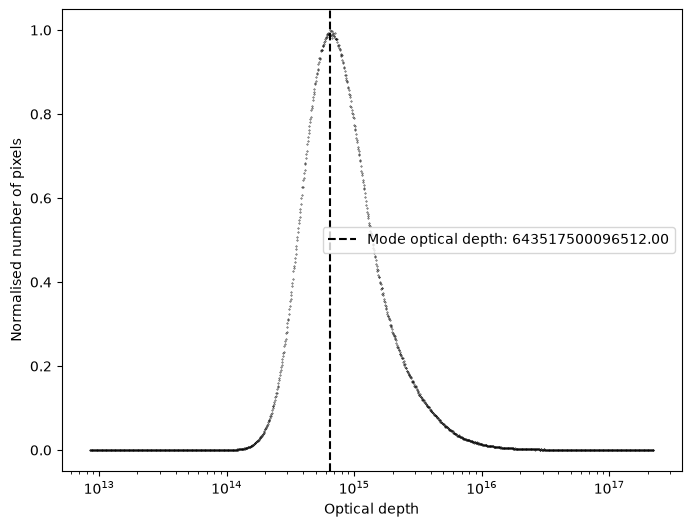

In [68]:
colte_path = "/Users/kyriakos.trakakis/COLTE/"
data_path  = "/Users/kyriakos.trakakis/Downloads/CHIMPS_COHRS/13CO/"

Tau_colte_file    = colte_path + "colte_CHIMPS_027_037_23arcsec_Tau13.fits"
N13_colte_file    = colte_path + "colte_CHIMPS_027_037_23arcsec_aligned_N13CO.fits"
SCIMES_file       = data_path  + "FGN_027_037_13CO_23arcsec_aligned_SNR_min_del_2_parallel_clusters.fits"

with fits.open(Tau_colte_file) as hdul:
    colte_tau        = hdul[0].data
    colte_tau_header = hdul[0].header

with fits.open(N13_colte_file) as hdul:
    colte_N13        = hdul[0].data
    colte_N13_header = hdul[0].header

with fits.open(SCIMES_file) as hdul:
    SCIMES_clouds        = hdul[0].data

mask_tau = (~np.isnan(colte_tau)) & (SCIMES_clouds > 0)
mask_N13 = (~np.isnan(colte_N13))# & (SCIMES_clouds > 0)

colte_tau = np.where(mask_tau, colte_tau, 0)
colte_tau = colte_tau[colte_tau > 0]

colte_N13 = np.where(mask_N13, colte_N13, 0)
colte_N13 = colte_N13[colte_N13 > 0]

#rat = colte_tau
rat = colte_N13

min_ratio = np.log10(rat).min()
max_ratio = np.log10(rat).max()

n_bins = math.ceil(2 * len(rat) ** 0.4)

log_bin_edges = np.linspace(min_ratio, max_ratio, n_bins + 1)

linear_bin_edges = 10**log_bin_edges

counts, _ = np.histogram(rat, bins=linear_bin_edges)

linear_bin_widths = linear_bin_edges[1:] - linear_bin_edges[:-1]

bin_centers_log = 0.5 * (log_bin_edges[:-1] + log_bin_edges[1:])
bin_centers_ratio = 10 ** bin_centers_log

peak_position = counts.argmax()
peak = bin_centers_ratio[peak_position]

plt.figure(figsize = (8,6))
plt.scatter(bin_centers_ratio, counts/counts.max(), s = 0.1, color = 'k')
plt.xlabel('Optical depth')
plt.ylabel('Normalised number of pixels')
plt.axvline(peak, color='k', ls='--', label=f'Mode optical depth: {peak:.2f}')
#plt.xlim([0,7])
plt.xscale('log')
plt.legend()

print(f"\n Optical depth peaks at {peak}")
print(f"\n Mean optical depth  is {np.log10(rat).mean()}")
print(f"\n Median optical depth  is {np.median(np.log10(rat))}")
print(f"\n Maximum optical depth  is {np.log10(rat).max()}")
print(f"\n Minimum optical depth  is {np.log10(rat).min()}")
print(f"\n Optical depth sigma is {np.std(rat)}")
plt.show()

In [70]:
threshold = 0.001

upper_limit = bin_centers_ratio[counts/counts.max() < threshold]
upper_limit = upper_limit[upper_limit > rat.mean()]
print(np.log10(upper_limit[0]))

lower_limit = bin_centers_ratio[counts/counts.max() < threshold]
lower_limit = lower_limit[lower_limit < rat.mean()]
print(np.log10(lower_limit[-1]))

16.527695
14.077841



 Ratio peaks at 7.337033140481156e+21

 Mean ratio  is 5.235627658652225e+21

 Median ratio  is 2.9370101120906937e+21

 Maximum ratio  is 1.110350688697172e+23

 Minimum ratio  is 2.2457514002208522e+19

 Ratio sigma is inf


/Users/kyriakos.trakakis/anaconda3/lib/python3.11/site-packages/numpy/_core/_methods.py:190: RuntimeWarning: overflow encountered in square
  x = um.square(x, out=x)


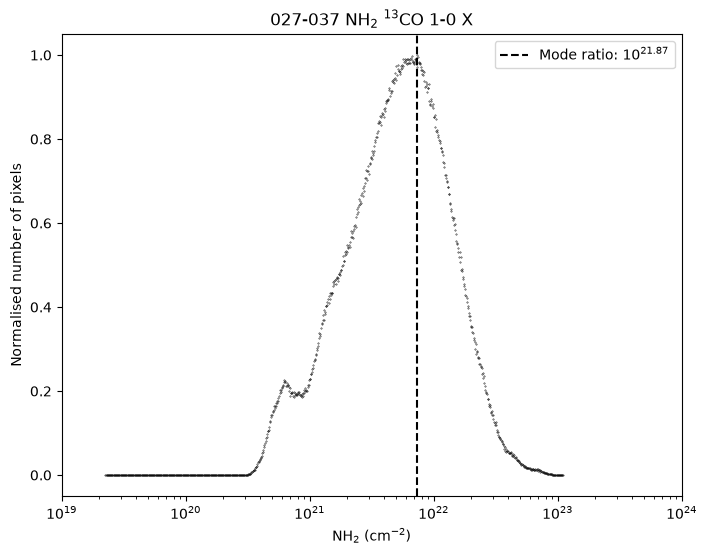


 Ratio peaks at 6.100616024682767e+21

 Mean ratio  is 5.82175876525552e+21

 Median ratio  is 2.574696929443621e+21

 Maximum ratio  is 2.5348103377248522e+23

 Minimum ratio  is 1.0660573592237061e+20

 Ratio sigma is inf


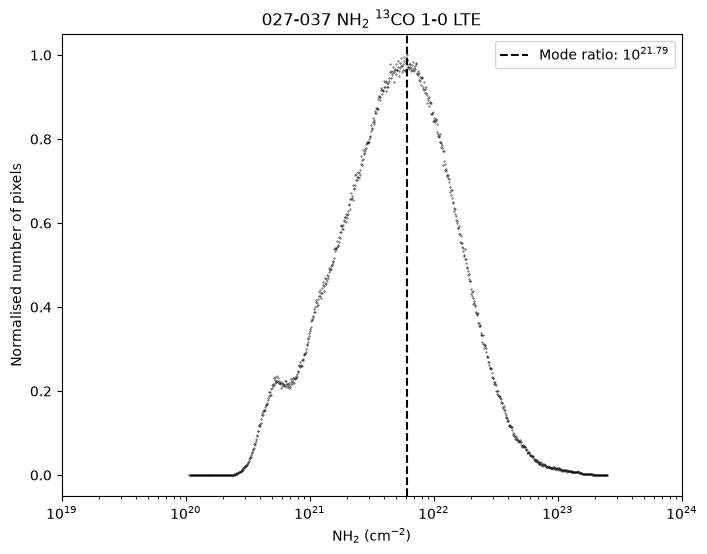


 Ratio peaks at 1.2014355464302772e+21

 Mean ratio  is 9.103410216530461e+20

 Median ratio  is 0.0

 Maximum ratio  is 2.1728562158170706e+23

 Minimum ratio  is 5.941947313673575e+19

 Ratio sigma is inf


/Users/kyriakos.trakakis/anaconda3/lib/python3.11/site-packages/numpy/_core/_methods.py:201: RuntimeWarning: overflow encountered in reduce
  ret = umr_sum(x, axis, dtype, out, keepdims=keepdims, where=where)


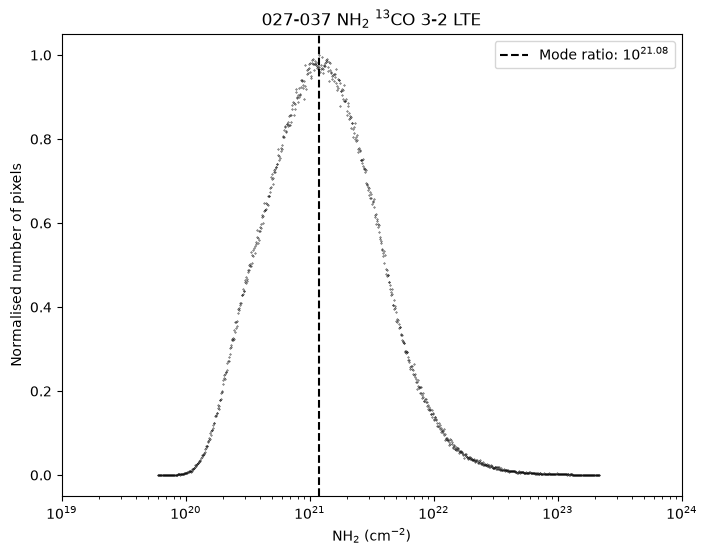


 Ratio peaks at 4.9804598962149e+21

 Mean ratio  is 4.5206398409855824e+21

 Median ratio  is 2.4524802130808773e+21

 Maximum ratio  is 9.110582086347058e+22

 Minimum ratio  is 4.3132322457216614e+17

 Ratio sigma is inf


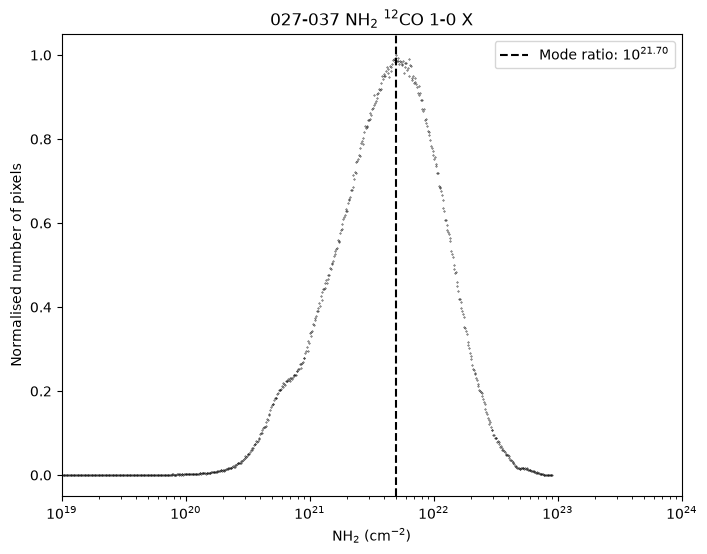


 Ratio peaks at 6.70411751504883e+21

 Mean ratio  is 6.812309177747011e+21

 Median ratio  is 1.8986314715565277e+21

 Maximum ratio  is 2.6293288026390794e+25

 Minimum ratio  is 4749993311207424.0

 Ratio sigma is inf


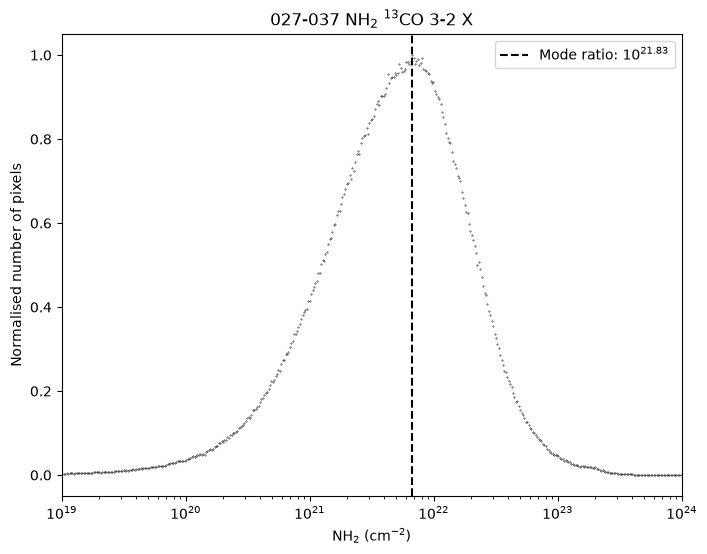


 Ratio peaks at 4.4874584448310234e+21

 Mean ratio  is 3.7031731767480775e+21

 Median ratio  is 1.757990810593188e+21

 Maximum ratio  is 1.2394396166163063e+23

 Minimum ratio  is 1.5544891098529792e+16

 Ratio sigma is inf


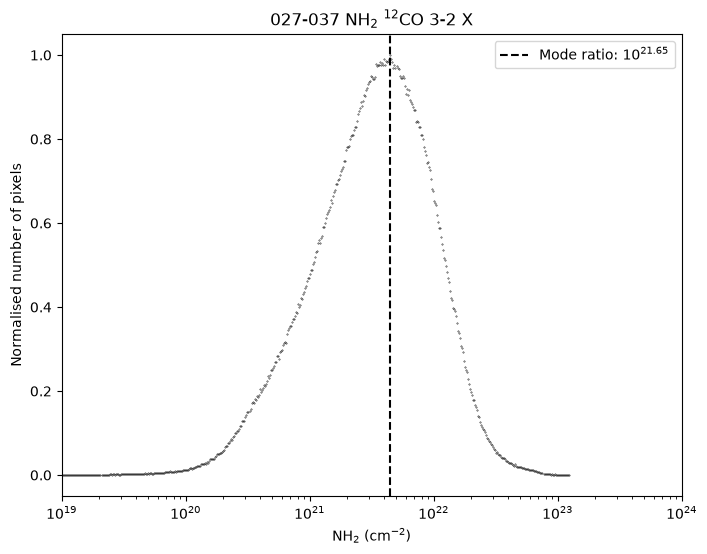

In [4]:
Density = {
    1: X_FGN,
    2: colte_FGN,
    3: colte_CHIMPS,
    4: X_FGN_12,
    5: X_CHIMPS,
    6: X_COHRS
}

pltitle = {
    1: r"027-037 NH$_2$ $^{13}$CO 1-0 X",
    2: r"027-037 NH$_2$ $^{13}$CO 1-0 LTE",
    3: r"027-037 NH$_2$ $^{13}$CO 3-2 LTE",
    4: r"027-037 NH$_2$ $^{12}$CO 1-0 X",
    5: r"027-037 NH$_2$ $^{13}$CO 3-2 X",
    6: r"027-037 NH$_2$ $^{12}$CO 3-2 X"
}

for i in range(len(Density)):

    rat = Density[i+1].ravel()

    min_ratio = np.log10(rat[rat>0].min())
    max_ratio = np.log10(rat.max())

    n_bins = math.ceil(2 * len(rat) ** 0.4)

    log_bin_edges = np.linspace(min_ratio, max_ratio, n_bins + 1)

    linear_bin_edges = 10**log_bin_edges

    counts, _ = np.histogram(rat, bins=linear_bin_edges)

    linear_bin_widths = linear_bin_edges[1:] - linear_bin_edges[:-1]

    bin_centers_log = 0.5 * (log_bin_edges[:-1] + log_bin_edges[1:])
    bin_centers_ratio = 10 ** bin_centers_log

    peak_position = counts.argmax()
    peak = bin_centers_ratio[peak_position]

    plt.figure(figsize = (8,6))
    plt.scatter(bin_centers_ratio, counts/counts.max(), s = 0.1, color = 'k')
    plt.xlabel('NH$_2$ (cm$^{-2}$)')
    plt.ylabel('Normalised number of pixels')
    plt.axvline(peak, color='k', ls='--', label=f'Mode ratio: $10^{{{np.log10(peak):.2f}}}$')
    plt.title(pltitle[i+1])
    plt.xlim([1e19, 1e24])
    plt.xscale('log')
    plt.legend()

    print(f"\n Ratio peaks at {peak}")
    print(f"\n Mean ratio  is {rat.mean()}")
    print(f"\n Median ratio  is {np.median(rat)}")
    print(f"\n Maximum ratio  is {rat.max()}")
    print(f"\n Minimum ratio  is {rat[rat>0].min()}")
    print(f"\n Ratio sigma is {np.std(rat)}")
    plt.show()


 Ratio peaks at 3.0852190722278294e+19

 Mean ratio  is 5.235627658652225e+21

 Median ratio  is 2.9370101120906937e+21

 Maximum ratio  is 1.110350688697172e+23

 Minimum ratio  is -7.723375560415041e+21

 Ratio sigma is inf


/var/folders/my/spqrhq7n74bcr2n7xfhc9hhr0000gp/T/ipykernel_7894/1624878214.py:30: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


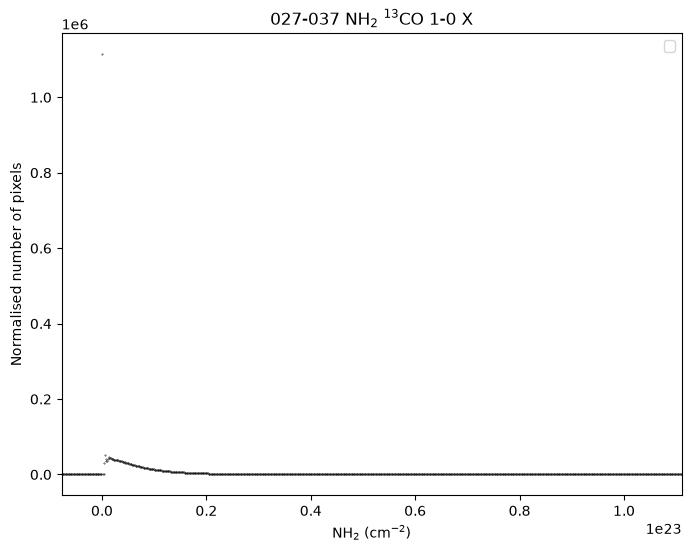


 Ratio peaks at 1.491064958769357e+20

 Mean ratio  is 5.82175876525552e+21

 Median ratio  is 2.574696929443621e+21

 Maximum ratio  is 2.5348103377248522e+23

 Minimum ratio  is 0.0

 Ratio sigma is inf


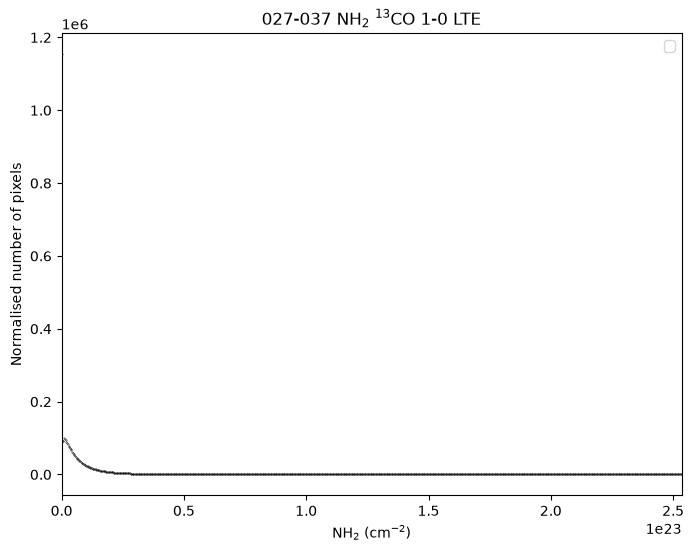


 Ratio peaks at 1.2781506893156503e+20

 Mean ratio  is 9.103410216530461e+20

 Median ratio  is 0.0

 Maximum ratio  is 2.1728562158170706e+23

 Minimum ratio  is 0.0

 Ratio sigma is inf


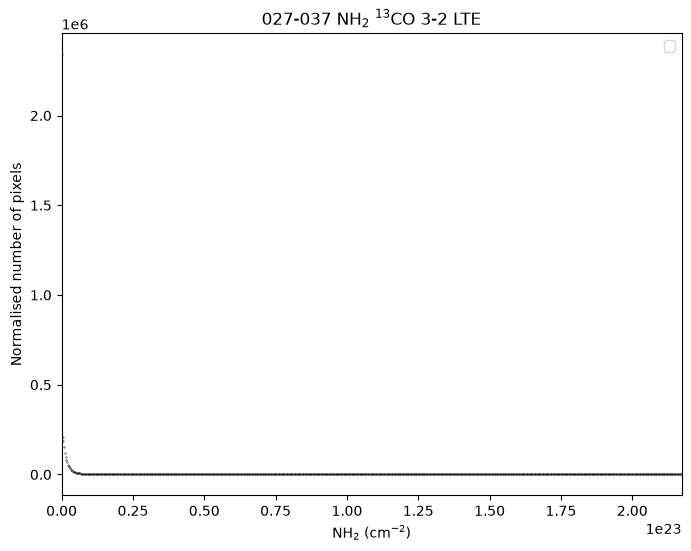


 Ratio peaks at 1.11247917995306e+20

 Mean ratio  is 4.5206398409855824e+21

 Median ratio  is 2.4524802130808773e+21

 Maximum ratio  is 9.110582086347058e+22

 Minimum ratio  is -1.958900826015819e+23

 Ratio sigma is inf


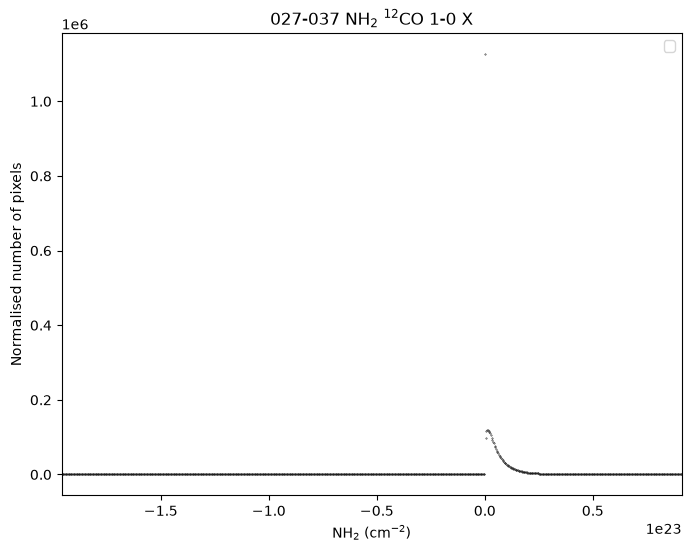


 Ratio peaks at 7.163965999250795e+20

 Mean ratio  is 6.812309177747011e+21

 Median ratio  is 1.8986314715565277e+21

 Maximum ratio  is 2.6293288026390794e+25

 Minimum ratio  is -1.800597497673895e+24

 Ratio sigma is inf


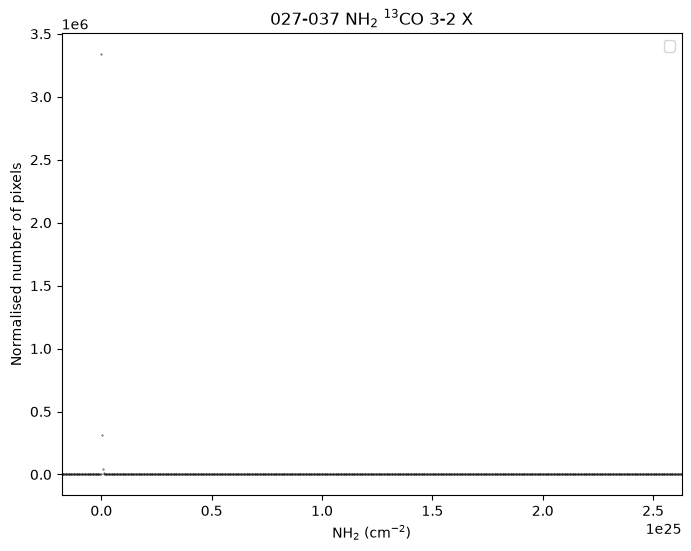


 Ratio peaks at 4.785074604081152e+18

 Mean ratio  is 3.7031731767480775e+21

 Median ratio  is 1.757990810593188e+21

 Maximum ratio  is 1.2394396166163063e+23

 Minimum ratio  is -4.638473429010988e+22

 Ratio sigma is inf


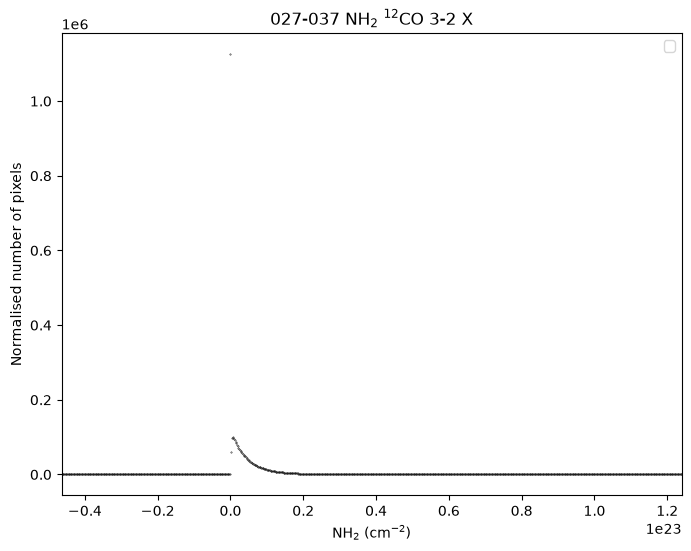

In [7]:
for i in range(len(Density)):

    rat = Density[i+1].ravel()

    min_ratio = rat.min()
    max_ratio = rat.max()


    n_bins = math.ceil(2 * len(rat) ** 0.4)

    bin_edges = np.linspace(min_ratio, max_ratio, n_bins + 1)


    counts, _ = np.histogram(rat, bins=bin_edges)

    linear_bin_widths = bin_edges[1:] - bin_edges[:-1]

    bin_centers = 0.5 * (bin_edges[:-1] + bin_edges[1:])

    peak_position = counts.argmax()
    peak = bin_centers[peak_position]

    plt.figure(figsize = (8,6))
    plt.scatter(bin_centers, counts, s = 0.1, color = 'k')
    plt.xlabel('NH$_2$ (cm$^{-2}$)')
    plt.ylabel('Normalised number of pixels')
    #plt.axvline(peak, color='k', ls='--', label=f'Mode ratio: $10^{{{np.log10(peak):.2f}}}$')
    plt.xlim([min_ratio,max_ratio])
    plt.title(pltitle[i+1])
    plt.legend()

    print(f"\n Ratio peaks at {peak}")
    print(f"\n Mean ratio  is {rat.mean()}")
    print(f"\n Median ratio  is {np.median(rat)}")
    print(f"\n Maximum ratio  is {rat.max()}")
    print(f"\n Minimum ratio  is {rat.min()}")
    print(f"\n Ratio sigma is {np.std(rat)}")
    plt.show()


 Ratio peaks at 7.337033140481156e+21

 Mean ratio  is 5.235627658652225e+21

 Median ratio  is 2.9370101120906937e+21

 Maximum ratio  is 1.110350688697172e+23

 Minimum ratio  is 2.2457514002208522e+19

 Ratio sigma is inf

 Sigma is 0.5175133943557739
372
578


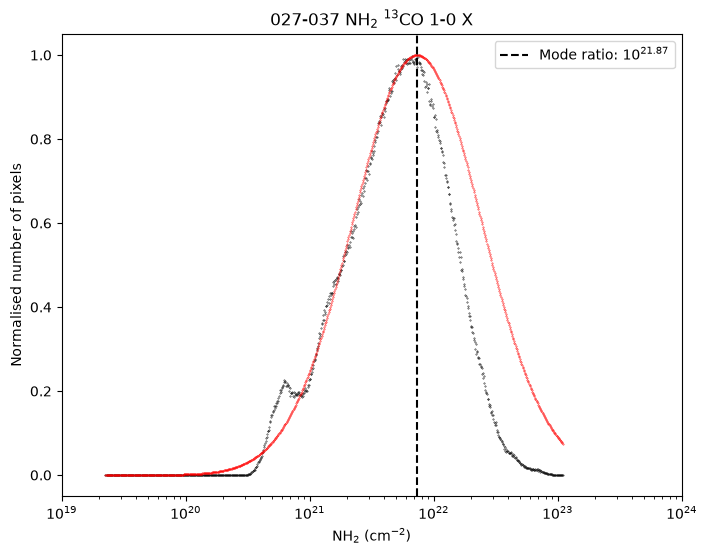


 Ratio peaks at 6.100616024682767e+21

 Mean ratio  is 5.82175876525552e+21

 Median ratio  is 2.574696929443621e+21

 Maximum ratio  is 2.5348103377248522e+23

 Minimum ratio  is 1.0660573592237061e+20

 Ratio sigma is inf

 Sigma is 0.537185549736023
208
442


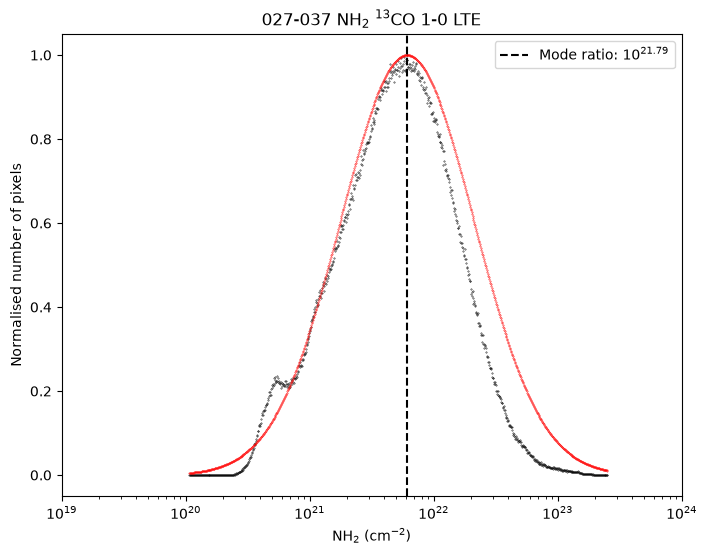


 Ratio peaks at 1.2014355464302772e+21

 Mean ratio  is 9.103410216530461e+20

 Median ratio  is 0.0

 Maximum ratio  is 2.1728562158170706e+23

 Minimum ratio  is 5.941947313673575e+19

 Ratio sigma is inf

 Sigma is 0.46285927295684814
120
311


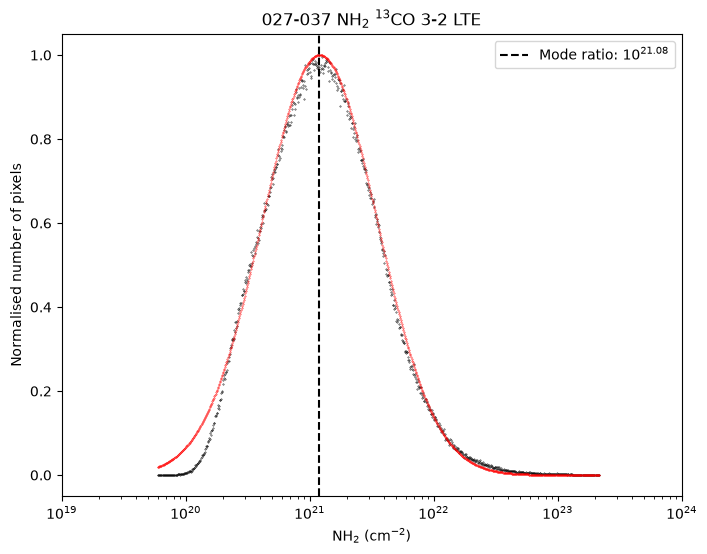


 Ratio peaks at 4.9804598962149e+21

 Mean ratio  is 4.5206398409855824e+21

 Median ratio  is 2.4524802130808773e+21

 Maximum ratio  is 9.110582086347058e+22

 Minimum ratio  is 4.3132322457216614e+17

 Ratio sigma is inf

 Sigma is 0.47108128666877747
518
648


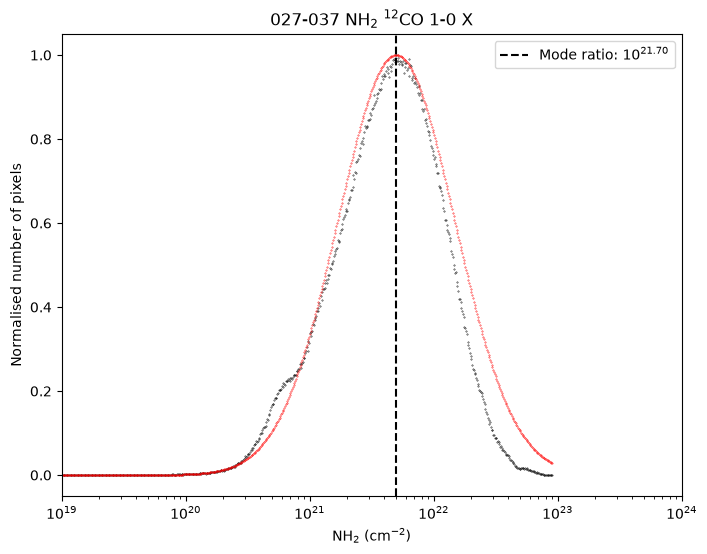


 Ratio peaks at 6.70411751504883e+21

 Mean ratio  is 6.812309177747011e+21

 Median ratio  is 1.8986314715565277e+21

 Maximum ratio  is 2.6293288026390794e+25

 Minimum ratio  is 4749993311207424.0

 Ratio sigma is inf

 Sigma is 0.643588125705719
439
536


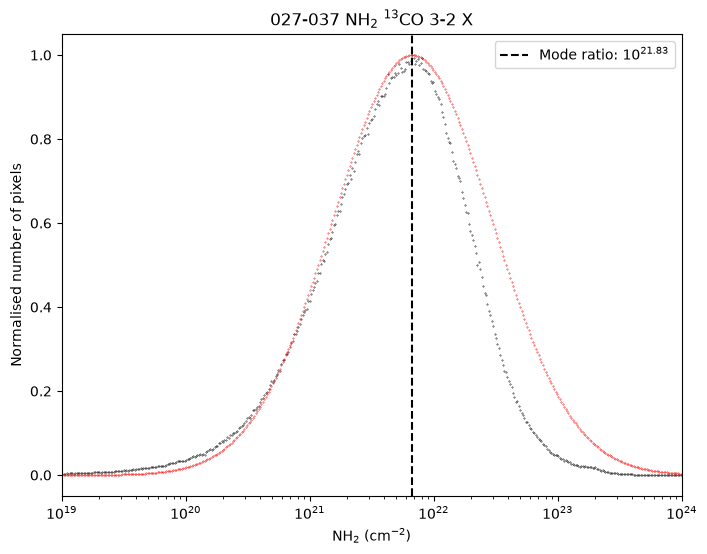


 Ratio peaks at 4.4874584448310234e+21

 Mean ratio  is 3.7031731767480775e+21

 Median ratio  is 1.757990810593188e+21

 Maximum ratio  is 1.2394396166163063e+23

 Minimum ratio  is 1.5544891098529792e+16

 Ratio sigma is inf

 Sigma is 0.5683989524841309
551
672


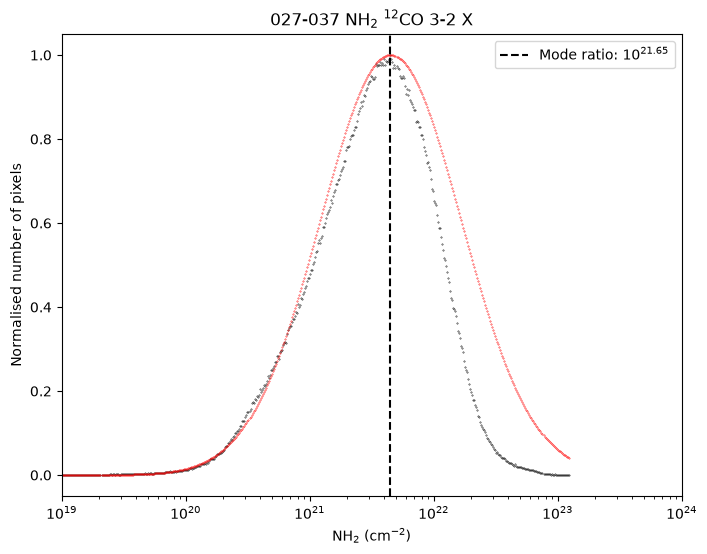

In [230]:
## Same cell as above making density histograms but this time I attempt to fit a Gaussian to the left side (first idea I had)

Density = {
    1: X_FGN,
    2: colte_FGN,
    3: colte_CHIMPS,
    4: X_FGN_12,
    5: X_CHIMPS,
    6: X_COHRS
}

pltitle = {
    1: r"027-037 NH$_2$ $^{13}$CO 1-0 X",
    2: r"027-037 NH$_2$ $^{13}$CO 1-0 LTE",
    3: r"027-037 NH$_2$ $^{13}$CO 3-2 LTE",
    4: r"027-037 NH$_2$ $^{12}$CO 1-0 X",
    5: r"027-037 NH$_2$ $^{13}$CO 3-2 X",
    6: r"027-037 NH$_2$ $^{12}$CO 3-2 X"
}



for i in range(len(Density)):

    rat = Density[i+1].ravel()

    min_ratio = np.log10(rat[rat>0].min())
    max_ratio = np.log10(rat.max())

    n_bins = math.ceil(2 * len(rat) ** 0.4)

    log_bin_edges = np.linspace(min_ratio, max_ratio, n_bins + 1)

    linear_bin_edges = 10**log_bin_edges

    counts, _ = np.histogram(rat, bins=linear_bin_edges)

    linear_bin_widths = linear_bin_edges[1:] - linear_bin_edges[:-1]

    bin_centers_log = 0.5 * (log_bin_edges[:-1] + log_bin_edges[1:])
    bin_centers_ratio = 10 ** bin_centers_log


    mode_bin = np.argmax(counts)
    rat_mode = bin_centers_log[mode_bin]
    peak = 10 ** rat_mode
    
    best_d = np.inf
    n_start = 0
    sigma = np.finfo(float).eps
    A = counts[mode_bin]
    y_fit = np.zeros_like(counts, dtype=float)
    
    for j in range(mode_bin + 1):
        n_start_j = j
        x_left = bin_centers_log[n_start_j:mode_bin + 1]
        y_left = counts[n_start_j:mode_bin + 1]
    
        if x_left.size < 10:
            continue
    
        sigma_j = np.sqrt(np.mean((x_left - rat_mode) ** 2))
        sigma_j = max(sigma_j, np.finfo(float).eps)    ## Smallest meaningful float
    
        g_left = np.exp(-0.5 * ((x_left - rat_mode) / sigma_j) ** 2)
        A_j = np.sum(y_left * g_left) / np.sum(g_left ** 2)
        y_left_fit = A_j * g_left
    
        weights = np.sqrt(np.maximum(y_left, 1))

        d = np.mean(((y_left_fit - y_left)/weights)**2)
    
        if d < best_d:
            best_d = d
            n_start = n_start_j
            sigma = sigma_j
            A = A_j
    
    g = np.exp(-0.5 * ((bin_centers_log - rat_mode) / sigma) ** 2)
    y_fit = A * g


    
    
################

    plt.figure(figsize = (8,6))
    plt.scatter(bin_centers_ratio, counts/counts.max(), s = 0.1, color = 'k')
    plt.scatter(bin_centers_ratio, y_fit/A, s = 0.1, color = 'red')
    plt.xlabel('NH$_2$ (cm$^{-2}$)')
    plt.ylabel('Normalised number of pixels')
    plt.axvline(peak, color='k', ls='--', label=f'Mode ratio: $10^{{{np.log10(peak):.2f}}}$')
    plt.title(pltitle[i+1])
    plt.xlim([1e19, 1e24])
    plt.xscale('log')
    plt.legend()

    print(f"\n Ratio peaks at {peak}")
    print(f"\n Mean ratio  is {rat.mean()}")
    print(f"\n Median ratio  is {np.median(rat)}")
    print(f"\n Maximum ratio  is {rat.max()}")
    print(f"\n Minimum ratio  is {rat[rat>0].min()}")
    print(f"\n Ratio sigma is {np.std(rat)}")
    print(f"\n Sigma is {sigma}")
    print(n_start)
    print(mode_bin)
    plt.show()

In [198]:
mode_bin

np.int64(672)


 Ratio peaks at 7.337033140481156e+21

 Mean ratio  is 5.235627658652225e+21

 Median ratio  is 2.9370101120906937e+21

 Maximum ratio  is 1.110350688697172e+23

 Minimum ratio  is 2.2457514002208522e+19

 Ratio sigma is inf

 Sigma is 0.31427299976348877
578
704


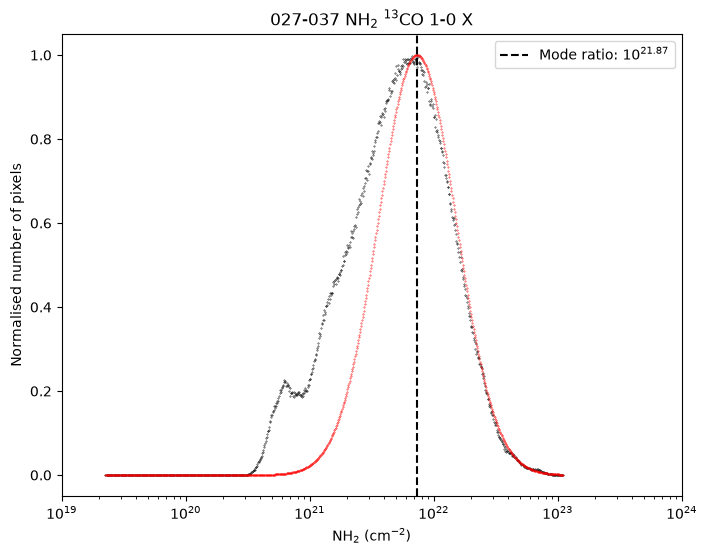


 Ratio peaks at 6.100616024682767e+21

 Mean ratio  is 5.82175876525552e+21

 Median ratio  is 2.574696929443621e+21

 Maximum ratio  is 2.5348103377248522e+23

 Minimum ratio  is 1.0660573592237061e+20

 Ratio sigma is inf

 Sigma is 0.41105690598487854
442
622


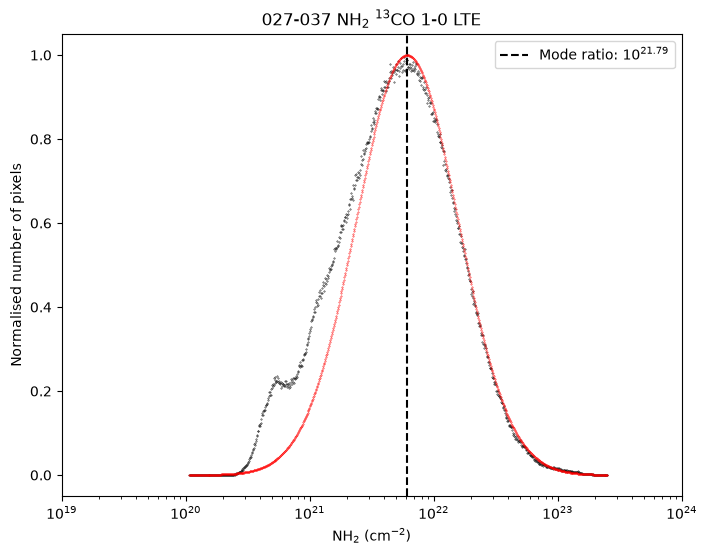


 Ratio peaks at 1.2014355464302772e+21

 Mean ratio  is 9.103410216530461e+20

 Median ratio  is 0.0

 Maximum ratio  is 2.1728562158170706e+23

 Minimum ratio  is 5.941947313673575e+19

 Ratio sigma is inf

 Sigma is 0.45317989587783813
311
499


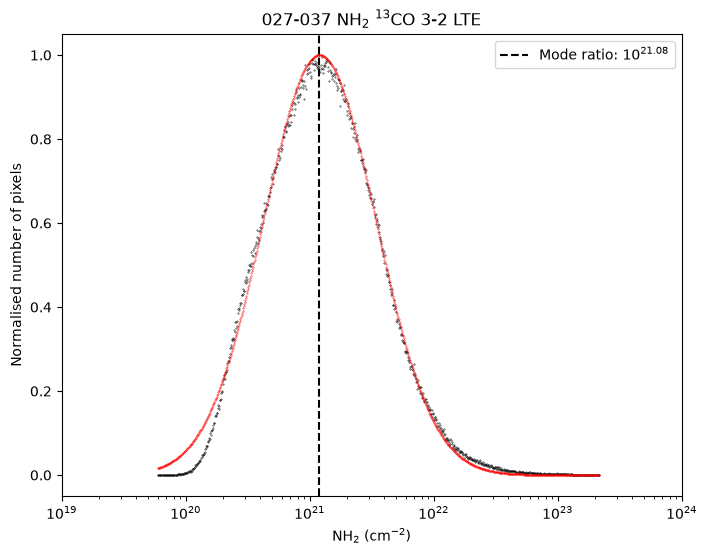


 Ratio peaks at 4.9804598962149e+21

 Mean ratio  is 4.5206398409855824e+21

 Median ratio  is 2.4524802130808773e+21

 Maximum ratio  is 9.110582086347058e+22

 Minimum ratio  is 4.3132322457216614e+17

 Ratio sigma is inf

 Sigma is 0.38427942991256714
648
755


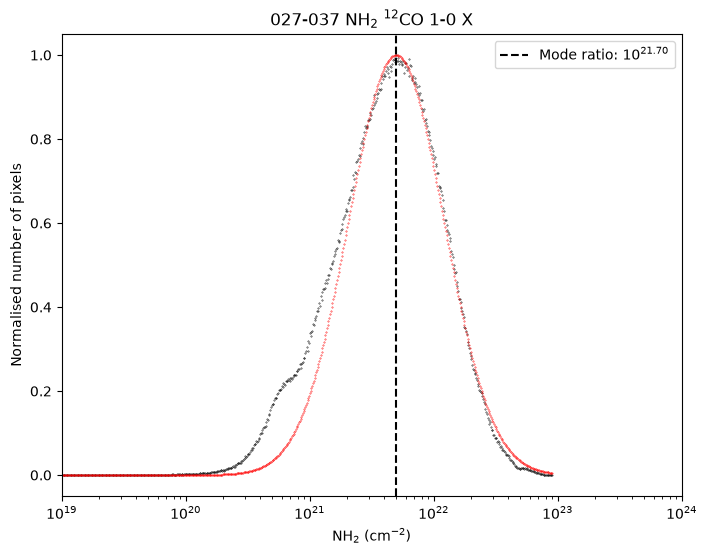


 Ratio peaks at 6.70411751504883e+21

 Mean ratio  is 6.812309177747011e+21

 Median ratio  is 1.8986314715565277e+21

 Maximum ratio  is 2.6293288026390794e+25

 Minimum ratio  is 4749993311207424.0

 Ratio sigma is inf

 Sigma is 0.45166870951652527
536
605


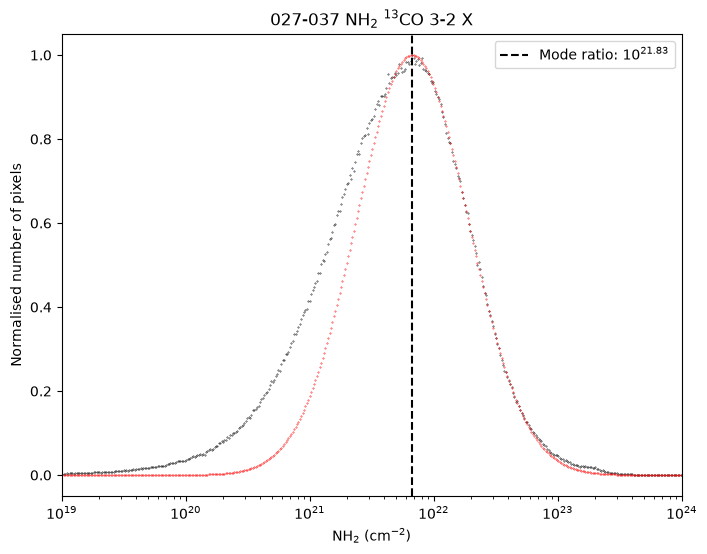


 Ratio peaks at 4.4874584448310234e+21

 Mean ratio  is 3.7031731767480775e+21

 Median ratio  is 1.757990810593188e+21

 Maximum ratio  is 1.2394396166163063e+23

 Minimum ratio  is 1.5544891098529792e+16

 Ratio sigma is inf

 Sigma is 0.37619748711586
672
753


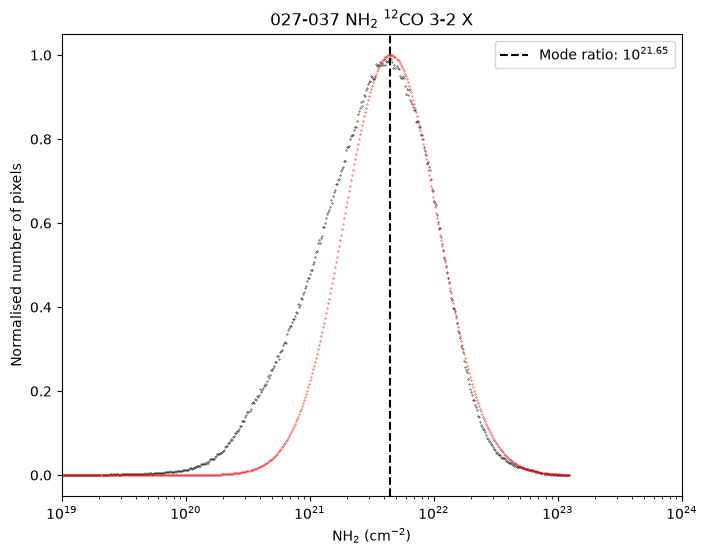

In [233]:
## Same cell as above making density histograms but this time I attempt to fit a Gaussian to the right side (escaping all noise)

Density = {
    1: X_FGN,
    2: colte_FGN,
    3: colte_CHIMPS,
    4: X_FGN_12,
    5: X_CHIMPS,
    6: X_COHRS
}

pltitle = {
    1: r"027-037 NH$_2$ $^{13}$CO 1-0 X",
    2: r"027-037 NH$_2$ $^{13}$CO 1-0 LTE",
    3: r"027-037 NH$_2$ $^{13}$CO 3-2 LTE",
    4: r"027-037 NH$_2$ $^{12}$CO 1-0 X",
    5: r"027-037 NH$_2$ $^{13}$CO 3-2 X",
    6: r"027-037 NH$_2$ $^{12}$CO 3-2 X"
}

for i in range(len(Density)):

    rat = Density[i+1].ravel()

    min_ratio = np.log10(rat[rat>0].min())
    max_ratio = np.log10(rat.max())

    n_bins = math.ceil(2 * len(rat) ** 0.4)

    log_bin_edges = np.linspace(min_ratio, max_ratio, n_bins + 1)

    linear_bin_edges = 10**log_bin_edges

    counts, _ = np.histogram(rat, bins=linear_bin_edges)

    linear_bin_widths = linear_bin_edges[1:] - linear_bin_edges[:-1]

    bin_centers_log = 0.5 * (log_bin_edges[:-1] + log_bin_edges[1:])
    bin_centers_ratio = 10 ** bin_centers_log
    mode_bin = np.argmax(counts)
    rat_mode = bin_centers_log[mode_bin]
    peak = 10 ** rat_mode


    best_d = np.inf
    n_end = len(counts)
    sigma = np.finfo(float).eps
    A = counts[mode_bin]
    y_fit = np.zeros_like(counts, dtype=float)

    # Fit only the right-hand side of the histogram (from the mode onward)
    for n_end_j in range(mode_bin + 2, len(counts) + 1):
        x_right = bin_centers_log[mode_bin:n_end_j]
        y_right = counts[mode_bin:n_end_j]

        if x_right.size < 10:
            continue

        sigma_j = np.sqrt(np.mean((x_right - rat_mode) ** 2))
        sigma_j = max(sigma_j, np.finfo(float).eps)

        g_right = np.exp(-0.5 * ((x_right - rat_mode) / sigma_j) ** 2)
        A_j = np.sum(y_right * g_right) / np.sum(g_right ** 2)
        y_right_fit = A_j * g_right

        weights = np.sqrt(np.maximum(y_right, 1))

        d = np.mean(((y_right_fit - y_right)/weights)**2)

        if d < best_d:
            best_d = d
            n_end = n_end_j
            sigma = sigma_j
            A = A_j

    g = np.exp(-0.5 * ((bin_centers_log - rat_mode) / sigma) ** 2)
    y_fit = A * g
                   
    
################
    

    peak_position = counts.argmax()
    peak = bin_centers_ratio[peak_position]

    plt.figure(figsize = (8,6))
    plt.scatter(bin_centers_ratio, counts/counts.max(), s = 0.1, color = 'k')
    plt.scatter(bin_centers_ratio, y_fit/A, s = 0.1, color = 'red')
    plt.xlabel('NH$_2$ (cm$^{-2}$)')
    plt.ylabel('Normalised number of pixels')
    plt.axvline(peak, color='k', ls='--', label=f'Mode ratio: $10^{{{np.log10(peak):.2f}}}$')
    plt.title(pltitle[i+1])
    plt.xlim([1e19, 1e24])
    plt.xscale('log')
    plt.legend()

    print(f"\n Ratio peaks at {peak}")
    print(f"\n Mean ratio  is {rat.mean()}")
    print(f"\n Median ratio  is {np.median(rat)}")
    print(f"\n Maximum ratio  is {rat.max()}")
    print(f"\n Minimum ratio  is {rat[rat>0].min()}")
    print(f"\n Ratio sigma is {np.std(rat)}")
    print(f"\n Sigma is {sigma}")
    print(mode_bin)
    print(n_end)
    plt.show()

# Comparing column densities pixel by pixel

In [79]:
data_path = "/Users/kyriakos.trakakis/Downloads/CHIMPS_COHRS/13CO/"
colte_path = "/Users/kyriakos.trakakis/COLTE/"

scimes = 1

# Original data
FGN_colte_file    = data_path + "FGN_027-037_colte_NH2_v0-120.fits"
CHIMPS_colte_file = data_path + "CHIMPS_027-037_colte_NH2_v0-120.fits"
FGN_X_file        = data_path + "FGN_027_037_13CO_23arcsec_aligned_NH2_X_v0-120.fits"
FGN_X_file_12     = data_path + "FGN_027_037_12CO_23arcsec_aligned_NH2_X_v0-120.fits"
CHIMPS_X_file     = data_path + "CHIMPS_027_037_13CO_23arcsec_aligned_NH2_X_v0-120.fits"
COHRS_X_file      = data_path + "COHRS_027_037_12CO_23arcsec_aligned_NH2_X_v0-120.fits"
W13_file          = data_path + "FGN_027_037_13CO_23arcsec_aligned_integrated_v0-120.fits"
W12_file          = data_path + "FGN_027_037_12CO_23arcsec_aligned_integrated_v0-120.fits"

# Scimes only
if scimes == 1:
    FGN_colte_file    = data_path + "FGN_027-037_colte_NH2_v0-120_scimes_mask.fits"
    CHIMPS_colte_file = data_path + "CHIMPS_027-037_colte_NH2_v0-120_scimes_mask.fits"
    FGN_X_file        = data_path + "FGN_027_037_13CO_23arcsec_aligned_NH2_X_v0-120_scimes_mask.fits"
    FGN_X_file_12     = data_path + "FGN_027_037_12CO_23arcsec_aligned_NH2_X_v0-120_scimes_mask.fits"
    CHIMPS_X_file     = data_path + "CHIMPS_027_037_13CO_23arcsec_aligned_NH2_X_v0-120_scimes_mask.fits"
    COHRS_X_file      = data_path + "COHRS_027_037_12CO_23arcsec_aligned_NH2_X_v0-120_scimes_mask.fits"
    W13_file          = data_path + "FGN_027_037_13CO_23arcsec_aligned_integrated_v0-120_scimes_mask.fits"
    W12_file          = data_path + "FGN_027_037_12CO_23arcsec_aligned_integrated_v0-120_scimes_mask.fits"

if scimes == 2:
    FGN_colte_file    = data_path + "/6 masses comparison COLTE 3-2 pixels/colte_FGN_037_047_13CO_23arcsec_aligned_NH2_integrated_cm-2.fits"
    CHIMPS_colte_file = data_path + "/6 masses comparison COLTE 3-2 pixels/colte_CHIMPS_037_047_13CO_23arcsec_aligned_NH2_integrated_cm-2.fits"
    FGN_X_file        = data_path + "/6 masses comparison COLTE 3-2 pixels/FGN_037_047_13CO_23arcsec_aligned_X_NH2_cm-2.fits"
    FGN_X_file_12     = data_path + "/6 masses comparison COLTE 3-2 pixels/FGN_037_047_12CO_23arcsec_aligned_X_NH2_cm-2.fits"
    CHIMPS_X_file     = data_path + "/6 masses comparison COLTE 3-2 pixels/CHIMPS_037_047_13CO_23arcsec_X_NH2_cm-2.fits"
    COHRS_X_file      = data_path + "/6 masses comparison COLTE 3-2 pixels/COHRS_037_047_12CO_23arcsec_aligned_X_NH2_cm-2.fits"


with fits.open(FGN_colte_file) as hdul:
    colte_FGN        = hdul[0].data
    colte_FGN_header = hdul[0].header 

with fits.open(CHIMPS_colte_file) as hdul:
    colte_CHIMPS        = hdul[0].data
    colte_CHIMPS_header = hdul[0].header 

with fits.open(FGN_X_file) as hdul:
    X_FGN        = hdul[0].data
    X_FGN_header = hdul[0].header 

with fits.open(FGN_X_file_12) as hdul:
    X_FGN_12        = hdul[0].data
    X_FGN_12_header = hdul[0].header 

with fits.open(CHIMPS_X_file) as hdul:
    X_CHIMPS        = hdul[0].data
    X_CHIMPS_header = hdul[0].header 

with fits.open(COHRS_X_file) as hdul:
    X_COHRS        = hdul[0].data
    X_COHRS_header = hdul[0].header 

with fits.open(W13_file) as hdul:
    W13        = hdul[0].data
    W13_header = hdul[0].header 

with fits.open(W12_file) as hdul:
    W12        = hdul[0].data
    W12_header = hdul[0].header 

# We don't check the colte files for NaNs, we made sure there are none earlier (right above density histograms)

mask = (colte_FGN>0) & (colte_CHIMPS>0) & (X_FGN>0) & (X_FGN_12 >0) & (X_CHIMPS>0) & (X_COHRS>0)

X_FGN        = np.where(mask, X_FGN, 0)
colte_FGN    = np.where(mask, colte_FGN, 0)
colte_CHIMPS = np.where(mask, colte_CHIMPS, 0)
X_FGN_12     = np.where(mask, X_FGN_12,0)
X_CHIMPS     = np.where(mask, X_CHIMPS,0)
X_COHRS      = np.where(mask, X_COHRS,0)
#W13          = np.where(mask, W13, 0)
#W12          = np.where(mask, W12, 0)


FGN_X_colte_ratio_raw        = np.where(mask, X_FGN/colte_FGN, 0)
FGN_X_CHIMPS_colte_ratio_raw = np.where(mask, X_FGN/colte_CHIMPS, 0)
FGN_CHIMPS_colte_ratio_raw   = np.where(mask, colte_FGN/colte_CHIMPS, 0)
#FGN_COLTE_W13_ratio_raw      = np.where(mask, colte_FGN / W13, 0)
#CHIMPS_COLTE_W13_ratio_raw   = np.where(mask, colte_CHIMPS / W13, 0)
#FGN_X_W13_ratio_raw          = np.where(mask, X_FGN / W13, 0)   ## This is silly, delete
FGN_COHRS_X_ratio_raw        = np.where(mask, X_FGN / X_COHRS, 0)


FGN_X_colte_ratio_name        = data_path + "027-037_NH2_ratio_FGN_X_COLTE.fits" 
FGN_X_CHIMPS_colte_ratio_name = data_path + "027-037_NH2_ratio_FGN_X_CHIMPS_COLTE.fits"
FGN_CHIMPS_colte_ratio_name   = data_path + "027-037_NH2_ratio_FGN_CHIMPS_LTE.fits"
#FGN_COLTE_W13_ratio_name     = data_path + "027-037_FGN_COLTE_NH2_W13_ratio.fits"
#CHIMPS_COLTE_W13_ratio_name   = data_path + "027-037_CHIMPS_COLTE_NH2_W13_ratio.fits"
FGN_COHRS_X_ratio_name        = data_path + "027-37_NH2_ratio_FGN_COHRS_X.fits"

hdu = fits.PrimaryHDU(FGN_X_colte_ratio_raw, header=colte_FGN_header)
#hdu.writeto(FGN_X_colte_ratio_name, overwrite=True)

hdu = fits.PrimaryHDU(FGN_X_CHIMPS_colte_ratio_raw, header=colte_FGN_header)
#hdu.writeto(FGN_X_CHIMPS_colte_ratio_name, overwrite=True)

hdu = fits.PrimaryHDU(FGN_CHIMPS_colte_ratio_raw, header=colte_FGN_header)
#hdu.writeto(FGN_CHIMPS_colte_ratio_name, overwrite=True)

#hdu = fits.PrimaryHDU(FGN_COLTE_W13_ratio_raw, header=colte_FGN_header)
#hdu.writeto(FGN_COLTE_W13_ratio_name, overwrite=True)

#hdu = fits.PrimaryHDU(CHIMPS_COLTE_W13_ratio_raw, header=colte_FGN_header)
#hdu.writeto(CHIMPS_COLTE_W13_ratio_name, overwrite=True)

hdu = fits.PrimaryHDU(FGN_COHRS_X_ratio_raw, header=colte_FGN_header)
hdu.writeto(FGN_COHRS_X_ratio_name, overwrite=True)


FGN_X_colte_ratio        = FGN_X_colte_ratio_raw[FGN_X_colte_ratio_raw!=0]
FGN_X_CHIMPS_colte_ratio = FGN_X_CHIMPS_colte_ratio_raw[FGN_X_CHIMPS_colte_ratio_raw!=0]
FGN_CHIMPS_colte_ratio   = FGN_CHIMPS_colte_ratio_raw[FGN_CHIMPS_colte_ratio_raw!=0]
#FGN_COLTE_W13_ratio      = FGN_COLTE_W13_ratio_raw[FGN_COLTE_W13_ratio_raw!=0]
#CHIMPS_COLTE_W13_ratio   = CHIMPS_COLTE_W13_ratio_raw[CHIMPS_COLTE_W13_ratio_raw!=0]
#FGN_X_W13_ratio          = FGN_X_W13_ratio_raw[FGN_X_W13_ratio_raw!=0]   ## This is silly, delete

/var/folders/my/spqrhq7n74bcr2n7xfhc9hhr0000gp/T/ipykernel_75687/2680142834.py:82: RuntimeWarning: invalid value encountered in divide
  FGN_X_colte_ratio_raw        = np.where(mask, X_FGN/colte_FGN, 0)
/var/folders/my/spqrhq7n74bcr2n7xfhc9hhr0000gp/T/ipykernel_75687/2680142834.py:83: RuntimeWarning: invalid value encountered in divide
  FGN_X_CHIMPS_colte_ratio_raw = np.where(mask, X_FGN/colte_CHIMPS, 0)
/var/folders/my/spqrhq7n74bcr2n7xfhc9hhr0000gp/T/ipykernel_75687/2680142834.py:84: RuntimeWarning: invalid value encountered in divide
  FGN_CHIMPS_colte_ratio_raw   = np.where(mask, colte_FGN/colte_CHIMPS, 0)
/var/folders/my/spqrhq7n74bcr2n7xfhc9hhr0000gp/T/ipykernel_75687/2680142834.py:88: RuntimeWarning: invalid value encountered in divide
  FGN_COHRS_X_ratio_raw        = np.where(mask, X_FGN / X_COHRS, 0)


# Ratio of densities

/var/folders/my/spqrhq7n74bcr2n7xfhc9hhr0000gp/T/ipykernel_75687/1858941200.py:32: RuntimeWarning: invalid value encountered in divide
  ratio_raw = np.where(mask, den1/den2, 0)



 Ratio peaks at 0.8137772475947486

 Mean ratio  is 0.920656144618988

 Median ratio  is 0.8249865770339966

 Maximum ratio  is 2864.046630859375

 Minimum ratio  is 0.05573153868317604

 Ratio sigma is 2.8947553634643555


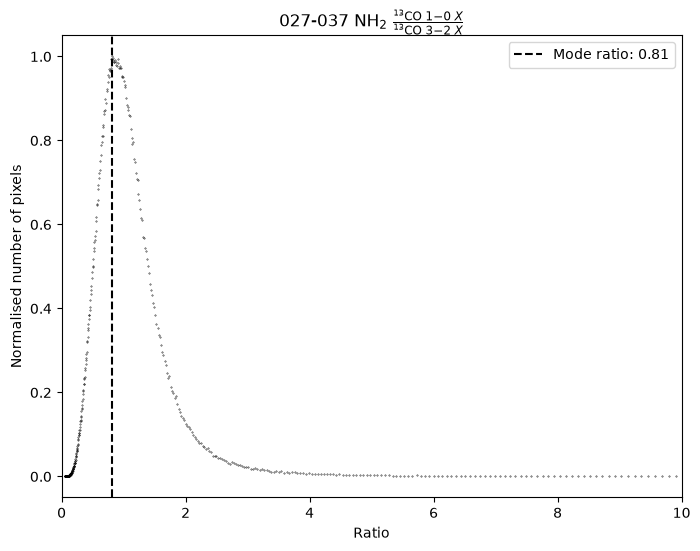

In [85]:
### This cell and the next do the same thing but this one is a bit more flexible


Density = {
    1: X_FGN,
    2: colte_FGN,
    3: colte_CHIMPS,
    4: X_FGN_12,
    5: X_CHIMPS,
    6: X_COHRS
}

den_titles = {
    1: r"^{13}\mathrm{CO}\ 1\!-\!0\ X",
    2: r"^{13}\mathrm{CO}\ 1\!-\!0\ LTE",
    3: r"^{13}\mathrm{CO}\ 3\!-\!2\ LTE",
    4: r"^{12}\mathrm{CO}\ 1\!-\!0\ X",
    5: r"^{13}\mathrm{CO}\ 3\!-\!2\ X",
    6: r"^{12}\mathrm{CO}\ 3\!-\!2\ X",
}

mode1 = 1
mode2 = 5

title = fr"027-037 NH$_2$ $\frac{{{den_titles[mode1]}}}{{{den_titles[mode2]}}}$"

den1 = Density[mode1]
den2 = Density[mode2]

mask = (den1>0) & (den2>0)

ratio_raw = np.where(mask, den1/den2, 0)
rat     = ratio_raw[ratio_raw!=0]

min_ratio = np.log10(rat.min())
#max_ratio = np.log10(rat.max()) 
max_ratio = np.log10(50)

n_bins = math.ceil(2 * len(rat) ** 0.4)

log_bin_edges = np.linspace(min_ratio, max_ratio, n_bins + 1)

linear_bin_edges = 10**log_bin_edges

counts, _ = np.histogram(rat, bins=linear_bin_edges)

linear_bin_widths = linear_bin_edges[1:] - linear_bin_edges[:-1]

bin_centers_log = 0.5 * (log_bin_edges[:-1] + log_bin_edges[1:])
bin_centers_ratio = 10 ** bin_centers_log

peak_position = counts.argmax()
peak = bin_centers_ratio[peak_position]

plt.figure(figsize = (8,6))
plt.scatter(bin_centers_ratio, counts/counts.max(), s = 0.1, color = 'k')
if (mode1 == 3) or (mode2 == 3):
    plt.xlim([0,50])
else:
    plt.xlim([0, 10])
plt.xlabel('Ratio')
plt.ylabel('Normalised number of pixels')
#if (mode == 4) or (mode == 5) or (mode == 6):
#    plt.axvline(peak, color='k', ls='--', label=f'Mode ratio: $10^{{{np.log10(peak):.2f}}}$')
#else:
plt.axvline(peak, color='k', ls='--', label=f'Mode ratio: {peak:.2f}')
plt.title(title)
plt.legend()

print(f"\n Ratio peaks at {peak}")
print(f"\n Mean ratio  is {rat.mean()}")
print(f"\n Median ratio  is {np.median(rat)}")
print(f"\n Maximum ratio  is {rat.max()}")
print(f"\n Minimum ratio  is {rat.min()}")
print(f"\n Ratio sigma is {np.std(rat)}")


 Ratio peaks at 6.929522612051744

 Mean ratio  is 9.232428550720215

 Median ratio  is 6.750131607055664

 Maximum ratio  is 341.2117004394531

 Minimum ratio  is 0.014752155169844627

 Ratio sigma is 9.18977165222168


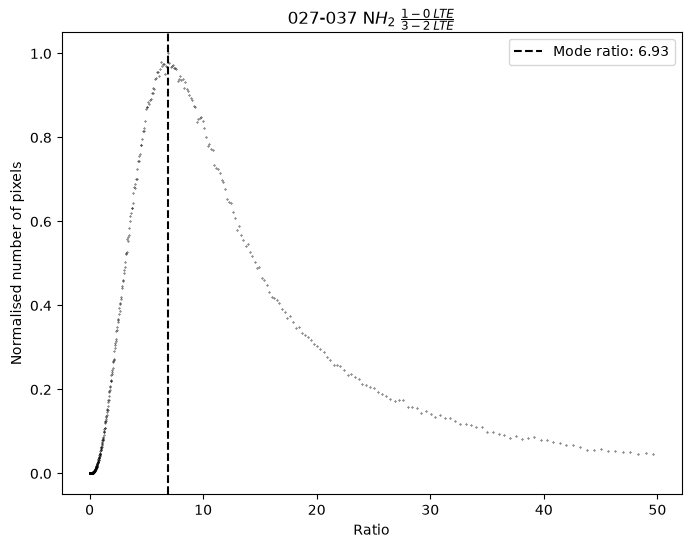

In [569]:
### This cell and the previous do the same thing but this one needs pre-calculated ratio sand is less flexible

mode = 3

Ratio = {
    1: FGN_X_colte_ratio,
    2: FGN_X_CHIMPS_colte_ratio,
    3: FGN_CHIMPS_colte_ratio,
    4: FGN_COLTE_W13_ratio ,
    5: CHIMPS_COLTE_W13_ratio,
    6: FGN_X_W13_ratio
}

pltitle = {
    1: r"027-037 N$H_2$ 1-0 $\frac{X}{LTE}$",
    2: r"027-037 NH$_2 \; \frac{1-0 \;X}{3-2\; LTE}$",
    3: r"027-037 N$H_2 \; \frac{1-0 \; LTE}{3-2\; LTE}$",
    4: r"027-037 $\frac{1-0\;LTE\;NH_2}{1-0\;W_{CO}}$",
    5: r"027-037 $\frac{3-2\;LTE\;NH_2}{1-0\;W_{CO}}$",
    6: "X-factor"
}

rat = Ratio[mode]

min_ratio = np.log10(rat.min())
if (mode == 1) or (mode == 2) or (mode == 3):
    max_ratio = np.log10(50) 
else:
    max_ratio = np.log10(rat.max())     ## Use this for modes 4,5

n_bins = math.ceil(2 * len(rat) ** 0.4)

log_bin_edges = np.linspace(min_ratio, max_ratio, n_bins + 1)

linear_bin_edges = 10**log_bin_edges

counts, _ = np.histogram(rat, bins=linear_bin_edges)

linear_bin_widths = linear_bin_edges[1:] - linear_bin_edges[:-1]

bin_centers_log = 0.5 * (log_bin_edges[:-1] + log_bin_edges[1:])
bin_centers_ratio = 10 ** bin_centers_log

peak_position = counts.argmax()
peak = bin_centers_ratio[peak_position]

plt.figure(figsize = (8,6))
plt.scatter(bin_centers_ratio, counts/counts.max(), s = 0.1, color = 'k')
plt.xlabel('Ratio')
plt.ylabel('Normalised number of pixels')
if (mode == 4) or (mode == 5) or (mode == 6):
    plt.axvline(peak, color='k', ls='--', label=f'Mode ratio: $10^{{{np.log10(peak):.2f}}}$')
else:
     plt.axvline(peak, color='k', ls='--', label=f'Mode ratio: {peak:.2f}')
plt.title(pltitle[mode])
if (mode ==4) or (mode ==5):
    plt.xscale('log')
plt.legend()

print(f"\n Ratio peaks at {peak}")
print(f"\n Mean ratio  is {rat.mean()}")
print(f"\n Median ratio  is {np.median(rat)}")
print(f"\n Maximum ratio  is {rat.max()}")
print(f"\n Minimum ratio  is {rat.min()}")
print(f"\n Ratio sigma is {np.std(rat)}")

In [293]:
Tex_file = colte_path + "colte_CHIMPS_027_037_23arcsec_aligned_Tex_snr5_weighted_v0-120.fits"

with fits.open(Tex_file) as hdul:
    Tex        = hdul[0].data
    Tex_header = hdul[0].header 

mask_Tex = mask & (~np.isnan(Tex))

In [294]:
FGN_X_colte_ratio_raw        = np.where(mask_Tex, X_FGN/colte_FGN, 0)
FGN_X_CHIMPS_colte_ratio_raw = np.where(mask_Tex, X_FGN/colte_CHIMPS, 0)
FGN_CHIMPS_colte_ratio_raw   = np.where(mask_Tex, colte_FGN/colte_CHIMPS, 0)
Tex_raw                      = np.where(mask_Tex, Tex, 0)

FGN_X_colte_ratio        = FGN_X_colte_ratio_raw[FGN_X_colte_ratio_raw!=0]
FGN_X_CHIMPS_colte_ratio = FGN_X_CHIMPS_colte_ratio_raw[FGN_X_CHIMPS_colte_ratio_raw!=0]
FGN_CHIMPS_colte_ratio   = FGN_CHIMPS_colte_ratio_raw[FGN_CHIMPS_colte_ratio_raw!=0]
Tex                      = Tex_raw[Tex_raw!=0]

ValueError: operands could not be broadcast together with shapes (1,608,6110) (1439348,) () 

Text(0.5, 1.0, ' T$_{ex}$ > 5 vs 027-037 N$H_2 \\; \\frac{1-0 \\; LTE}{3-2\\; LTE}$')

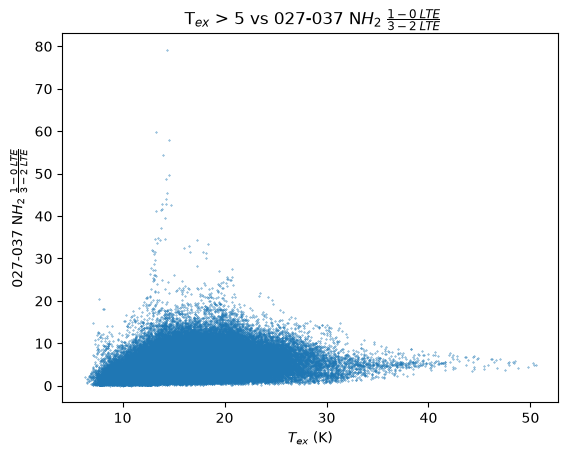

In [21]:
mode = 3
thresh = 5

Ratio = {
    1: FGN_X_colte_ratio,
    2: FGN_X_CHIMPS_colte_ratio,
    3: FGN_CHIMPS_colte_ratio
}

pltitle = {
    1: r"027-037 N$H_2$ 1-0 $\frac{X}{LTE}$",
    2: r"027-037 NH$_2 \; \frac{1-0 \;X}{3-2\; LTE}$",
    3: r"027-037 N$H_2 \; \frac{1-0 \; LTE}{3-2\; LTE}$"
}

rat = Ratio[mode]

filename = {
    1: f"027-037_Tex_NH2_ratio_FGN_X_colte_Tex{thresh}.png",
    2: f"027-037_Tex_NH2_ratio_FGN_X_CHIMPS_colte_Tex{thresh}.png",
    3: f"027-037_Tex_NH2_ratio_FGN_CHIMPS_colte_Tex{thresh}.png"
}

if np.count_nonzero(Tex>thresh) < 1000:
    size = 1
else:
    size = 0.1 

plt.scatter(Tex[Tex>thresh], rat[Tex>thresh], s =size)
plt.xlabel(r"$T_{ex}$ (K)")
plt.ylabel(pltitle[mode])
plt.title(r" T$_{ex}$" + f" > {thresh} vs {pltitle[mode]}")
#plt.savefig(data_path + filename[mode])

In [22]:
np.count_nonzero(Tex > 35)

np.int64(290)

In [23]:
weights = Tex**(3/4)

fit, cov = np.polyfit(Tex, rat, 1, w=weights, cov=True)

m, b = fit
m_err, b_err = np.sqrt(np.diag(cov))

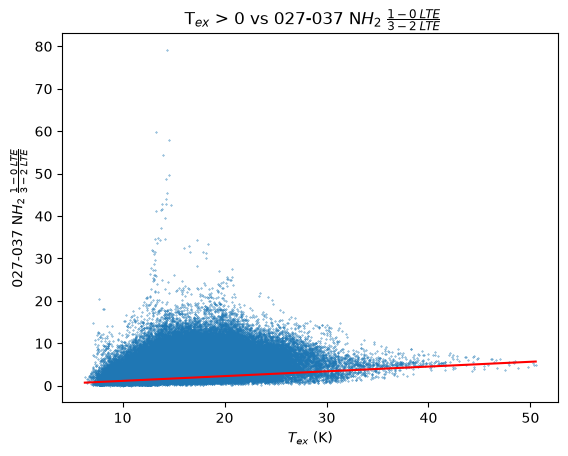

In [24]:
mode = 3
thresh = 0

Ratio = {
    1: FGN_X_colte_ratio,
    2: FGN_X_CHIMPS_colte_ratio,
    3: FGN_CHIMPS_colte_ratio
}

pltitle = {
    1: r"027-037 N$H_2$ 1-0 $\frac{X}{LTE}$",
    2: r"027-037 NH$_2 \; \frac{1-0 \;X}{3-2\; LTE}$",
    3: r"027-037 N$H_2 \; \frac{1-0 \; LTE}{3-2\; LTE}$"
}

rat = Ratio[mode]

filename = {
    1: f"027-037_Tex_NH2_ratio_FGN_X_colte_Tex{thresh}.png",
    2: f"027-037_Tex_NH2_ratio_FGN_X_CHIMPS_colte_Tex{thresh}.png",
    3: f"027-037_Tex_NH2_ratio_FGN_CHIMPS_colte_Tex{thresh}.png"
}

if np.count_nonzero(Tex>thresh) < 1000:
    size = 1
else:
    size = 0.1 

T_fit = np.linspace(Tex[Tex>thresh].min(), Tex[Tex>thresh].max(), len(Tex[Tex>thresh]))

plt.scatter(Tex[Tex>thresh], rat[Tex>thresh], s =size)
plt.xlabel(r"$T_{ex}$ (K)")
plt.ylabel(pltitle[mode])
plt.title(r" T$_{ex}$" + f" > {thresh} vs {pltitle[mode]}")
plt.plot(T_fit, m*T_fit + b_err, color = 'red')

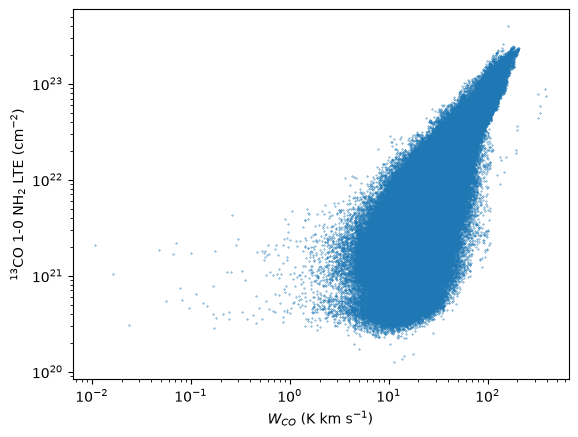

In [25]:
plt.scatter(W13, colte_FGN, s=0.1)
plt.xlabel('$W_{CO}$ (K km s$^{-1}$)')
plt.ylabel('$^{13}$CO 1-0 NH$_2$ LTE (cm$^{-2}$)') 
plt.yscale('log')
plt.xscale('log')

/var/folders/my/spqrhq7n74bcr2n7xfhc9hhr0000gp/T/ipykernel_16705/3020509518.py:9: RuntimeWarning: divide by zero encountered in log10
  log_X       = np.log10(X_FGN)
/var/folders/my/spqrhq7n74bcr2n7xfhc9hhr0000gp/T/ipykernel_16705/3020509518.py:10: RuntimeWarning: divide by zero encountered in log10
  log_COLTE_1 = np.log10(colte_FGN)
/var/folders/my/spqrhq7n74bcr2n7xfhc9hhr0000gp/T/ipykernel_16705/3020509518.py:11: RuntimeWarning: divide by zero encountered in log10
  log_COLTE_3 = np.log10(colte_CHIMPS)
/var/folders/my/spqrhq7n74bcr2n7xfhc9hhr0000gp/T/ipykernel_16705/3020509518.py:12: RuntimeWarning: divide by zero encountered in log10
  log_W13     = np.log10(W13)
/var/folders/my/spqrhq7n74bcr2n7xfhc9hhr0000gp/T/ipykernel_16705/3020509518.py:13: RuntimeWarning: divide by zero encountered in log10
  log_W12     = np.log10(W12)
/var/folders/my/spqrhq7n74bcr2n7xfhc9hhr0000gp/T/ipykernel_16705/3020509518.py:14: RuntimeWarning: divide by zero encountered in log10
  log_Tex     = np.log10

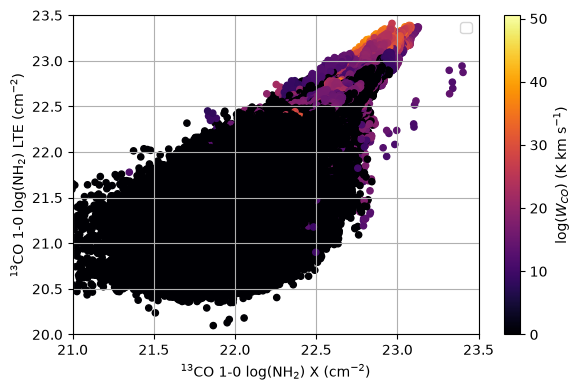

Best fit: log(NH2_X) = 0.4983 * log_(NH2_COLTE) + 11.2532


/var/folders/my/spqrhq7n74bcr2n7xfhc9hhr0000gp/T/ipykernel_16705/3020509518.py:53: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


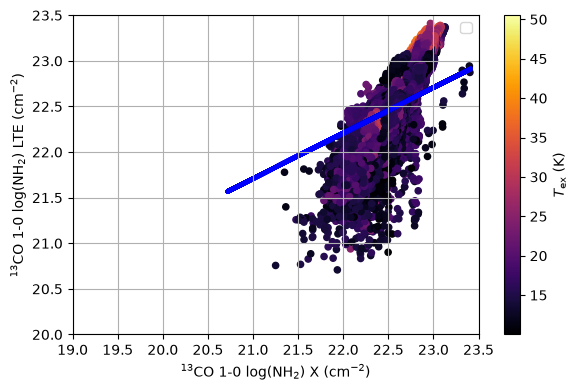

/var/folders/my/spqrhq7n74bcr2n7xfhc9hhr0000gp/T/ipykernel_16705/3020509518.py:67: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


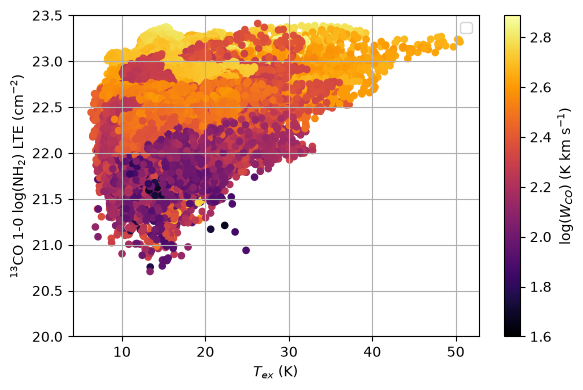

In [112]:
X_FGN        = np.where(mask, X_FGN, 0)
colte_FGN    = np.where(mask, colte_FGN, 0)
colte_CHIMPS = np.where(mask, colte_CHIMPS, 0)
W13          = np.where(mask, W13, 0)
W12          = np.where(mask, W12, 0)
Tex          = np.where((mask), Tex_raw, 0)


log_X       = np.log10(X_FGN)
log_COLTE_1 = np.log10(colte_FGN)
log_COLTE_3 = np.log10(colte_CHIMPS)
log_W13     = np.log10(W13) 
log_W12     = np.log10(W12) 
log_Tex     = np.log10(Tex)

mask_W12 = Tex > 10
# Define weights (e.g., directly or 1/W if you want inverse-distance weight)
#weights = R  # or 1/W, or 1/W**2 depending on purpose

#weights = (log_COLTE_1[mask_W12]-log_COLTE_1[mask_W12].max())
fit = np.polyfit(log_X[mask_W12], log_COLTE_1[mask_W12], 1)
a_fit, c_fit = fit
N_model = np.linspace(log_COLTE_1[mask_W12].min(),log_COLTE_1[mask_W12].max(), len(log_COLTE_1[mask_W12]))

# Plot
plt.figure(figsize=(6, 4))
#plt.scatter(log_X[mask_W12], log_COLTE_1[mask_W12], c=log_W12[mask_W12], cmap='inferno', s=20)#, edgecolor='k')
plt.scatter(log_X, log_COLTE_1, c=Tex, cmap='inferno', s=20)#, edgecolor='k')
plt.xlabel('$^{13}$CO 1-0 log(NH$_2$) X (cm$^{-2}$)')
plt.ylabel('$^{13}$CO 1-0 log(NH$_2$) LTE (cm$^{-2}$)')
plt.grid(True)
plt.xlim([21,23.5])
plt.ylim([20, 23.5])
plt.colorbar(label='log($W_{CO}$) (K km s$^{-1}$)')
plt.legend()
plt.tight_layout()
plt.show()

print(f"Best fit: log(NH2_X) = {a_fit:.4f} * log_(NH2_COLTE) + {c_fit:.4f}")
plt.figure(figsize=(6, 4))
sc = plt.scatter(log_X[mask_W12], log_COLTE_1[mask_W12],
                 c=Tex[mask_W12], cmap='inferno', s=20)
#plt.scatter(log_X[mask_W12], log_COLTE_1[mask_W12], c=Tex[mask_W12], cmap='inferno', s=20)#, edgecolor='k')
plt.scatter(N_model, N_model*a_fit + c_fit, s= 2, color = 'blue')
#plt.scatter(log_X, log_COLTE_1, c=log_W12, cmap='inferno', s=20)#, edgecolor='k')
plt.xlabel('$^{13}$CO 1-0 log(NH$_2$) X (cm$^{-2}$)')
plt.ylabel('$^{13}$CO 1-0 log(NH$_2$) LTE (cm$^{-2}$)')
plt.grid(True)
plt.xlim([19,23.5])
plt.ylim([20, 23.5])
plt.colorbar(sc, label=r'$T_{\rm ex}$ (K)')
#plt.colorbar(label='log($W_{CO}$) (K km s$^{-1}$)')
plt.legend()
plt.tight_layout()
plt.show()

plt.figure(figsize=(6, 4))
plt.scatter(Tex[Tex>0], log_COLTE_1[Tex>0], c=log_W12[Tex>0], cmap='inferno', s=20)#, edgecolor='k')
#plt.xlabel('$^{13}$CO 1-0 log(NH$_2$) X (cm$^{-2}$)')
plt.xlabel('$T_{ex}$ (K)')
plt.ylabel('$^{13}$CO 1-0 log(NH$_2$) LTE (cm$^{-2}$)')
plt.grid(True)
#plt.xlim([21,23.5])
plt.ylim([20, 23.5])
plt.colorbar(label='log($W_{CO}$) (K km s$^{-1}$)')
#plt.xscale('log')
plt.legend()
plt.tight_layout()
plt.show()

In [27]:
print(f"\n W12 peaks at {stats.mode(W12[W12>0])[0]}")
print(f"\n Mean W12  is {W12.mean()}")
print(f"\n Median W12  is {np.median(W12)}")
print(f"\n Maximum W12  is {W12.max()}")
print(f"\n Minimum W12  is {W12.min()}")
print(f"\n W12 sigma is {np.std(W12)}")


 W12 peaks at 138.49591064453125

 Mean W12  is 103.04244995117188

 Median W12  is 65.94401550292969

 Maximum W12  is 942.54052734375

 Minimum W12  is 0.0

 W12 sigma is 120.97393798828125


In [289]:
print(np.count_nonzero(Tex[Tex>0]))
print(np.count_nonzero(Tex[Tex>10])/np.count_nonzero(Tex))

135227
0.9548389005154296


# NH2 Ratio Evans plots

In [352]:
data_path = "/Users/kyriakos.trakakis/Downloads/CHIMPS_COHRS/13CO/"
colte_path = "/Users/kyriakos.trakakis/COLTE/"

# Original data
#FGN_colte_file    = colte_path + "colte_FGN_027_037_23arcsec_aligned_N13CO.fits"
#CHIMPS_colte_file = colte_path + "colte_CHIMPS_027_037_23arcsec_aligned_N13CO.fits"
#FGN_X_file        = data_path + "FGN_027_037_13CO_23arcsec_aligned_3D_XNH2.fits"

# Scimes mask
#FGN_colte_file    = colte_path + "colte_FGN_027_037_23arcsec_aligned_N13CO_scimes_mask.fits"   ## These 3 files live on data02 CHIMPS_COHRS/13CO/misc
#CHIMPS_colte_file = colte_path + "colte_CHIMPS_027_037_23arcsec_aligned_N13CO_scimes_mask.fits"
#FGN_X_file        = data_path + "FGN_027_037_13CO_23arcsec_aligned_3D_XNH2_scimes_mask.fits"
SNR_1_file        = data_path + "FGN_027_037_13CO_23arcsec_aligned_SNR.fits"
SNR_3_file        = data_path + "CHIMPS_027_037_13CO_23arcsec_aligned_SNR.fits"
FGN_13CO_file     = data_path + "FGN_027_037_13CO_23arcsec_aligned.fits"
CHIMPS_13CO_file  = data_path + "CHIMPS_027_037_13CO_23arcsec_aligned.fits"

with fits.open(FGN_colte_file) as hdul:
    colte_FGN        = hdul[0].data
    header_2D        = hdul[0].header 
colte_FGN = colte_FGN * 930000

with fits.open(CHIMPS_colte_file) as hdul:
    colte_CHIMPS        = hdul[0].data
colte_CHIMPS = colte_CHIMPS * 930000

with fits.open(FGN_X_file) as hdul:
    X_FGN        = hdul[0].data

with fits.open(SNR_1_file) as hdul:
    SNR_1        = hdul[0].data

with fits.open(SNR_3_file) as hdul:
    SNR_3        = hdul[0].data

with fits.open(FGN_13CO_file) as hdul:
    FGN_13       = hdul[0].data
    header_3D    = hdul[0].header

with fits.open(CHIMPS_13CO_file) as hdul:
    CHIMPS_13    = hdul[0].data

region = SNR_1_file.split("_")[2] + "_" + SNR_1_file.split("_")[3]
iso    = SNR_1_file.split("_")[4][:2]

In [86]:
densities = {
    1: X_FGN,
    2: colte_CHIMPS,
    3: colte_FGN
}

labels = {
    1: "1-0\; X",
    2: "3-2\; COLTE",
    3: "1-0\; COLTE"
}

data_cubes = {
    1: FGN_13,
    2: CHIMPS_13,
    3: FGN_13
    
}

snr_cubes = {
    1: SNR_1,
    2: SNR_3,
    3: SNR_1
}

den1 = 3
den2 = 2

rmin = 1
rmax = 15
snrmax = 10

# =====================================================
# REGION NOISE VALUES
# =====================================================


sigma = {
    1: 0.54,
    2: 0.6,
    3: 0.54
}

vlow, vhigh = 70, 110


# =====================================================
# VELOCITY AXIS
# =====================================================

nchan = SNR_1.shape[0]

crval3 = header_3D["CRVAL3"]
crpix3 = header_3D["CRPIX3"]
cdelt3 = header_3D["CDELT3"]

channels = np.arange(nchan)
vel = crval3 + (channels + 1 - crpix3) * cdelt3

if abs(cdelt3) > 100:
    vel = vel / 1000.0


# =====================================================
# LOOP THROUGH VELOCITY BLOCKS
# =====================================================

bins = np.arange(vlow, vhigh + 10, 10)

den_cube1 = densities[den1]
den_cube2 = densities[den2]

dat_cube1 = data_cubes[den1]
dat_cube2 = data_cubes[den2]

for i in range(len(bins) - 1):

    v0 = bins[i]
    v1 = bins[i + 1]

    mask_v = (vel >= v0) & (vel < v1)

    cube1 = den_cube1[mask_v, :, :]
    cube2 = den_cube2[mask_v, :, :]

    cube_data1 = dat_cube1[mask_v,:,:]
    cube_data2 = dat_cube2[mask_v,:,:]

    # -----------------------------------------
    # Integrated intensities
    # -----------------------------------------

    I1 = np.nansum(cube1, axis=0)
    I2 = np.nansum(cube2, axis=0)

    ID1 = np.nansum(cube_data1, axis=0)
    ID2 = np.nansum(cube_data2, axis=0)  

    # -----------------------------------------
    # Ratio
    # -----------------------------------------

    ratio = np.full_like(I1, np.nan, dtype=float)

    good = (I2 > 0) & (~np.isnan(I1)) & (~np.isnan(I2))
    ratio[good] = I1[good] / I2[good]
    print(np.nanpercentile(ratio, [1, 50, 99]))

    # -----------------------------------------
    # SNR estimate
    # -----------------------------------------
    
    sigma1_eff = sigma[den1] * np.sqrt(nchan)
    sigma2_eff = sigma[den2] * np.sqrt(nchan)

    a = sigma1_eff / ID1
    b = sigma2_eff / ID2

    snr = 1.0 / (a**2 + b**2)
    print(np.nanpercentile(snr, [1, 50, 99]))

    # -----------------------------------------
    # HSV conversion
    # -----------------------------------------

    ratio_clip = np.clip(ratio, rmin, rmax)

   # H = (ratio_clip - rmin) / (rmax - rmin)
    scaled = (ratio_clip - rmin)/(rmax-rmin)
    H = 0.8 * scaled

    # Original white noise
    S = np.clip(snr, 1, snrmax)
    S = (S-1)/(snrmax-1)

    V = np.ones_like(H)

    # grey at SNR=0, bright at high SNR
    #S = np.clip(snr, 0, snrmax) / snrmax
    #V = 0.5 + 0.5 * S

    HSV = np.dstack((H, S, V))
    RGB = hsv_to_rgb(HSV)

    RGB[np.isnan(ratio)] = 1

    # -----------------------------------------
    # Plot
    # -----------------------------------------

    wcs2d = WCS(header_3D).celestial
    header2d = wcs2d.to_header()

    fig = plt.figure(figsize=(9, 7))
    ax = fig.add_subplot(111, projection=wcs2d)

    ax.imshow(RGB, origin="lower")

    ax.set_xlabel("Galactic Longitude")
    ax.set_ylabel("Galactic Latitude")

    ax.set_title(
    fr"$^{{13}}$CO $\frac{{{labels[den1]}}}{{{labels[den2]}}}$"
    f"\t {v0}–{v1} km/s"
)
    region_mod = region.replace("_","-")
    plt.tight_layout()
    plt.show()
# =====================================================
# 2D LEGEND
# =====================================================

nx, ny = 300, 300

ratio_vals = np.linspace(rmin, rmax, nx)
snr_vals   = np.linspace(1, snrmax, ny)  # Can also do 0,snrmax

RR, SS = np.meshgrid(ratio_vals, snr_vals)

scaled_leg = (RR - rmin) / (rmax - rmin)
H_leg = 0.8 * scaled_leg

#H_leg = (RR - rmin) / (rmax - rmin)
#S_leg = SS / snrmax  # For gray
S_leg = (SS - 1) / 9.0
#V_leg = 0.5 + 0.5 * S_leg # For gray
V_leg = np.ones_like(H_leg)

HSV_leg = np.dstack((H_leg, S_leg, V_leg))
RGB_leg = hsv_to_rgb(HSV_leg)

plt.figure(figsize=(8, 6))
plt.imshow(
    RGB_leg,
    origin="lower",
    aspect="auto",
    extent=[rmin, rmax, 1, snrmax]  # Can also do 0, snrmax
)

plt.xlabel(
    fr"$^{{13}}$CO $\frac{{{labels[den1]}}}{{{labels[den2]}}}$ NH$_2$ Ratio"
)
plt.ylabel("S/N")
plt.title("Evans Plot Colour Legend")

plt.tight_layout()
plt.show()

NameError: name 'FGN_13' is not defined

# Density vs Density Ratio

In [491]:
scimes = 1

# Original data
FGN_colte_file    = data_path + "FGN_027-037_colte_NH2_v0-120.fits"
CHIMPS_colte_file = data_path + "CHIMPS_027-037_colte_NH2_v0-120.fits"
FGN_X_file        = data_path + "FGN_027_037_13CO_23arcsec_aligned_NH2_X_v0-120.fits"
FGN_X_file_12     = data_path + "FGN_027_037_12CO_23arcsec_aligned_NH2_X_v0-120.fits"
CHIMPS_X_file     = data_path + "CHIMPS_027_037_13CO_23arcsec_aligned_NH2_X_v0-120.fits"
COHRS_X_file      = data_path + "COHRS_027_037_12CO_23arcsec_aligned_NH2_X_v0-120.fits"
W13_file          = data_path + "FGN_027_037_13CO_23arcsec_aligned_integrated_v0-120.fits"
W12_file          = data_path + "FGN_027_037_12CO_23arcsec_aligned_integrated_v0-120.fits"
W18_file          = data_path + "FGN_027_037_C18O_23arcsec_aligned_integrated_v0-120.fits"
Tex_file          = colte_path + "colte_CHIMPS_027_037_23arcsec_aligned_Tex_snr5_weighted_v0-120.fits"

# Scimes only
if scimes == 1:
    FGN_colte_file    = data_path + "FGN_027-037_colte_NH2_v0-120_scimes_mask.fits"
    CHIMPS_colte_file = data_path + "CHIMPS_027-037_colte_NH2_v0-120_scimes_mask.fits"
    FGN_X_file        = data_path + "FGN_027_037_13CO_23arcsec_aligned_NH2_X_v0-120_scimes_mask.fits"
    FGN_X_file_12     = data_path + "FGN_027_037_12CO_23arcsec_aligned_NH2_X_v0-120_scimes_mask.fits"
    CHIMPS_X_file     = data_path + "CHIMPS_027_037_13CO_23arcsec_aligned_NH2_X_v0-120_scimes_mask.fits"
    COHRS_X_file      = data_path + "COHRS_027_037_12CO_23arcsec_aligned_NH2_X_v0-120_scimes_mask.fits"
    W13_file          = data_path + "FGN_027_037_13CO_23arcsec_aligned_integrated_v0-120_scimes_mask.fits"
    W12_file          = data_path + "FGN_027_037_12CO_23arcsec_aligned_integrated_v0-120_scimes_mask.fits"
    W18_file          = data_path + "FGN_027_037_C18O_23arcsec_aligned_integrated_v0-120_scimes_mask.fits"
    Tex_file          = colte_path + "colte_CHIMPS_027_037_23arcsec_aligned_Tex_scimes_mask_weighted_v0-120.fits"


with fits.open(FGN_colte_file) as hdul:
    colte_FGN        = hdul[0].data
    colte_FGN_header = hdul[0].header 

with fits.open(CHIMPS_colte_file) as hdul:
    colte_CHIMPS        = hdul[0].data
    colte_CHIMPS_header = hdul[0].header 

with fits.open(FGN_X_file) as hdul:
    X_FGN        = hdul[0].data
    X_FGN_header = hdul[0].header 

with fits.open(FGN_X_file_12) as hdul:
    X_FGN_12        = hdul[0].data
    X_FGN_12_header = hdul[0].header 

with fits.open(CHIMPS_X_file) as hdul:
    X_CHIMPS        = hdul[0].data
    X_CHIMPS_header = hdul[0].header 

with fits.open(COHRS_X_file) as hdul:
    X_COHRS        = hdul[0].data
    X_COHRS_header = hdul[0].header 

with fits.open(W13_file) as hdul:
    W13        = hdul[0].data
    W13_header = hdul[0].header 

with fits.open(W12_file) as hdul:
    W12        = hdul[0].data
    W12_header = hdul[0].header 

with fits.open(Tex_file) as hdul:
    Tex        = hdul[0].data
    Tex_header = hdul[0].header 

with fits.open(W18_file) as hdul:
    W18        = hdul[0].data
    W18_header = hdul[0].header 

# We don't check the colte files for NaNs, we made sure there are none earlier (right above density histograms)

mask = (colte_FGN>0) & (colte_CHIMPS>0) & (X_FGN>0) & (X_FGN_12>0) & (X_CHIMPS>0) & (X_COHRS>0)

X_FGN        = np.where(mask, X_FGN, 0)
colte_FGN    = np.where(mask, colte_FGN, 0)
colte_CHIMPS = np.where(mask, colte_CHIMPS, 0)
X_FGN_12     = np.where(mask, X_FGN_12,0)
X_CHIMPS     = np.where(mask, X_CHIMPS,0)
X_COHRS      = np.where(mask, X_COHRS,0)
W13          = np.where(mask, W13, 0)
W12          = np.where(mask, W12, 0)
W18          = np.where(mask, W18, 0)
Tex_raw      = np.where(mask, Tex, 0)
inten_ratio  = np.where(mask, W12/ W13, 0)


Density = {
    1: X_FGN,
    2: colte_FGN,
    3: colte_CHIMPS,
    4: X_FGN_12,
    5: X_CHIMPS,
    6: X_COHRS,
    7: inten_ratio
}

xtitles = {
    1: r"NH$_2$ $^{13}$CO 1-0 X (cm$^{-2}$)",
    2: r"NH$_2$ $^{13}$CO 1-0 COLTE (cm$^{-2}$)",
    3: r"NH$_2$ $^{13}$CO 3-2 COLTE (cm$^{-2}$)",
    4: r"NH$_2$ $^{12}$CO 1-0 X (cm$^{-2}$)",
    5: r"NH$_2$ $^{13}$CO 3-2 X (cm$^{-2}$)",
    6: r"NH$_2$ $^{12}$CO 3-2 X (cm$^{-2}$)",
    7: r"027-037 1-0 $\frac{W^{12}CO}{W^{13}CO}$" 
}

den_titles = {
    1: r"^{13}\mathrm{CO}\ 1\!-\!0\ X",
    2: r"^{13}\mathrm{CO}\ 1\!-\!0\ LTE",
    3: r"^{13}\mathrm{CO}\ 3\!-\!2\ LTE",
    4: r"^{12}\mathrm{CO}\ 1\!-\!0\ X",
    5: r"^{13}\mathrm{CO}\ 3\!-\!2\ X",
    6: r"^{12}\mathrm{CO}\ 3\!-\!2\ X",
    7: r"R^{12/13} 1\!-\!0"
}

/var/folders/my/spqrhq7n74bcr2n7xfhc9hhr0000gp/T/ipykernel_16705/3210884990.py:83: RuntimeWarning: invalid value encountered in divide
  inten_ratio  = np.where(mask, W12/ W13, 0)


/var/folders/my/spqrhq7n74bcr2n7xfhc9hhr0000gp/T/ipykernel_16705/3725908971.py:14: RuntimeWarning: invalid value encountered in divide
  ratio_raw       = np.where(mask, R1/R2, 0)


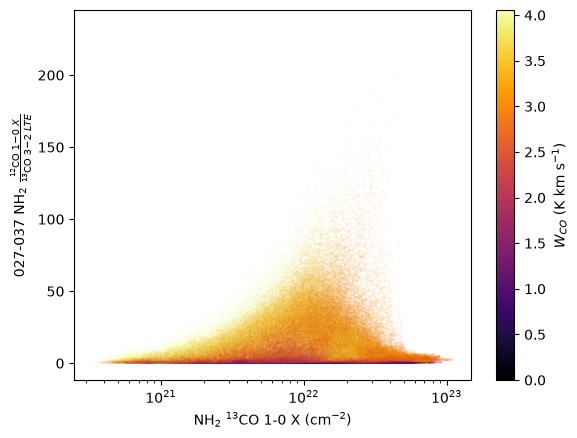

In [572]:
# I broke this into 2, no need to load everything every time we plot

modeD  = 1  ## This is the density on the plot
modeR1 = 4  ## Numerator of the ratio
modeR2 = 3  ## Denominator of the ratio

ytitle = fr"027-037 NH$_2$ $\frac{{{den_titles[modeR1]}}}{{{den_titles[modeR2]}}}$"
xtitle = xtitles[modeD]

D  = Density[modeD]
R1 = Density[modeR1]
R2 = Density[modeR2]

ratio_raw       = np.where(mask, R1/R2, 0)


mask = (D>0) & (R1>0) & (R2>0) & (ratio_raw!=0) & (inten_ratio!=0)

R            = np.where(mask, ratio_raw, 0)
D            = np.where(mask, D, 0)
X_FGN        = np.where(mask, X_FGN, 0)
colte_FGN    = np.where(mask, colte_FGN, 0)
colte_CHIMPS = np.where(mask, colte_CHIMPS, 0)
X_FGN_12     = np.where(mask, X_FGN_12,0)
X_CHIMPS     = np.where(mask, X_CHIMPS,0)
X_COHRS      = np.where(mask, X_COHRS,0)
W13          = np.where(mask, W13, 0)
W12          = np.where(mask, W12, 0)
W18          = np.where(mask, W18, 0)
Tex          = np.where(mask, Tex, 0)
inten_ratio  = np.where(mask, inten_ratio, 0)


colour = inten_ratio

#plt.scatter(density[W12 > W12.mean()+ 3 * np.std(W12)], ratio[W12>W12.mean()+ 3 * np.std(W12)], s=0.1, c = W12[W12>W12.mean()+ 3 * np.std(W12)], cmap = 'inferno')
#plt.scatter(density[Tex_masked > Tex_masked.mean()+ 2 * np.std(Tex_masked)], ratio[Tex_masked>Tex_masked.mean()+ 2 * np.std(Tex_masked)], s=0.1, c = Tex_masked[Tex_masked>Tex_masked.mean()+ 2 * np.std(Tex_masked)], cmap = 'inferno')
plt.scatter(D, R, s=0.001, c = colour, vmin =0, vmax = colour.max()/4, cmap = 'inferno')
plt.xlabel(xtitle)
#plt.xlim([1e20, 2e23])
#plt.ylim([0,2])
#plt.xlim([1e22, 1.5e23])
#plt.ylim([0,5])
plt.colorbar(label='$W_{CO}$ (K km s$^{-1}$)')
#plt.colorbar(label='T$_{ex}$ (K')
plt.ylabel(ytitle)
plt.xscale('log')

In [128]:
W12.mean() + 2 * np.std(W12)

np.float32(97.01959)

In [361]:
ratio.max()

np.float32(25.250658)